In [7]:
# ============================================================================
#           MAIN LIBRARIES
# ============================================================================

import numpy as np
import matplotlib.pyplot as plt;  from matplotlib.pyplot import subplots
import scipy ; from scipy.stats import norm
import os
import scipy.optimize; from scipy.optimize import curve_fit ; from scipy import signal
import csv 
import sys
from PIL import Image ; import cv2
import skimage as ski
from skimage import restoration, filters, morphology , io
from scipy import ndimage,linalg, optimize
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


#Import other programs in .py
#sys.path.append('/home/kheya/pyblish/'); 
#import publish # type: ignore
sys.path.insert(1, r'C:\Users\nicol\Desktop\NICOLAS\RICM\AHmed code')
from Utilities import Fit_Gaussian # type: ignore

#### RICM Model PARAMETERS

In [8]:
# ============================================================================
#           PARAMETERS FOR RICM MODEL
# ============================================================================

n_0 = 1.525    # Glass coverslip
n_1 = 1.3335   # OUTER buffer 
n_2 = 1.486    # Vesicle membrane
n_3 = 1.3415   # INNER buffer

LAMBDA_LIGHT = 546 # nm
ILLUMINATION_NUMERICAL_APERTURE = 0.64 # Medium AD aperture: INA = 0.64 (diameter AD = 1.19 mm) ; Max AD aperture: INA = 1.25
MEMBRANE_THICKNESS = 4 # nm
HOW_MANY_REFLECTIONS = 5 # number of reflections to consider in the model: selcet 3 or 5

SHOT_NOISE_PARAM_A = 0.43  # shot noise: sigma = A sqrt(I) + B
SHOT_NOISE_PARAM_B = 4.55  # shot noise 

sys.path.insert(1, r'C:\Users\nicol\Desktop\NICOLAS\RICM')
if HOW_MANY_REFLECTIONS == 3:
    import RICM_model_3LayersReflections as RICM # type: ignore
elif HOW_MANY_REFLECTIONS == 5:
    import RICM_model_5LayersReflections as RICM # type: ignore
    WATER_LAYER_THICKNESS = 1     # nm, thickness of the water layer

In [9]:
# Functions for calculating the I(h) curve with INA>0
def r_ij(ni, nj):
    # normal-incidence Fresnel amplitude coefficient 
    return (ni - nj) / (ni + nj)

def R_airy(r12, r23, delta):
    # exact thin-film (Airy) reflection coefficient of the membrane
    exponential = np.exp(1j * delta)  # complex number
    return (r12 + r23 * exponential) / (1 + r12 * r23 * exponential)

def membrane_R( n1, n2, n3, d=MEMBRANE_THICKNESS , lam=LAMBDA_LIGHT):
    r12, r23 = r_ij(n1, n2), r_ij(n2, n3)
    delta = 4 * np.pi * n2 * d / lam
    return R_airy(r12, r23, delta)

def I_norm_closed(h,  n0, n1, n2, n3, INA,  d=MEMBRANE_THICKNESS, lam=LAMBDA_LIGHT):
    # closed-form normalized intensity (I - I_bg)/I_bg, with I_bg = r01^2 I0
    h = np.asarray(h, float)
    r01 = r_ij(n0, n1)
    R = membrane_R(n1, n2, n3, d, lam)
    alpha = np.arcsin(INA / n1)
    s2 = np.sin(alpha / 2) ** 2
    k = 2 * np.pi * n1 / lam
    y = 2 * k * h * s2
    sinc = np.sinc(y / np.pi)                 # = sin(y)/y, safe at y=0
    Phi = 2 * k * h * (1 - s2) + np.angle(R)
    rho = (1 - r01**2) * np.abs(R) / r01
    h0 = (np.pi - np.angle(R))/(2*k)
    return rho**2 + 2 * rho * sinc * np.cos(Phi), rho, h0


def add_film(r_near, r_far, TT_far, delta):
    """
    Put a film in front of a stack (Airy recursion). Light comes from the glass side.
      r_near : reflection coefficient of the interface on the glass side of the film
      r_far  : reflection coefficient of everything beyond the film (away from the glass), seen from inside the film
      TT_far : two-way transmission (there and back) of everything beyond the film
      delta  : round-trip phase in the film, 4*pi*n*d*cos(theta_film)/lam
    Returns (r_stack, TT_stack) of "film + everything beyond it", seen from the glass side.
    """
    e = np.exp(1j * delta)
    D = 1 + r_near * r_far * e                      # multiple reflections inside the film
    r_stack = (r_near + r_far * e) / D              # the far reflection has crossed the film twice -> phase e^{i delta}
    TT_stack = (1 - r_near**2) * TT_far * e / D**2
    return r_stack, TT_stack


def I_norm_numeric(h, lam, n0, n_w, n_outer, n_membrane , n_inner, d_h2o, d, INA, how_many_reflections, angular=True, N=5000):
    """
    Normalized RICM intensity (I - I_bg) / I_bg.

    how_many_reflections = 3 : glass | outer buffer (h) | membrane (d) | inner buffer
    how_many_reflections = 5 : glass | water layer (d_h2o) | membrane (d) | outer buffer (h) | membrane (d) | inner buffer
                               (the membrane under the buffer layer has the same n2 and d as the vesicle membrane;
                                the water layer has index n_h2o, default n1)

    The integral over the illumination cone
        I = ∫ |E(theta)|^2 sin(theta) dtheta / ∫ sin(theta) dtheta
    is approximated by a weighted sum  I = sum_i W_i * |E_i|^2  over N ray angles.
    """

    if how_many_reflections not in (3, 5):
        raise ValueError("how_many_reflections must be 3 or 5")

    h = np.atleast_1d(np.asarray(h, float))           # heights, shape (n_h,)
    k = 2 * np.pi * n_outer / lam                          # wavevector in the outer buffer

    # ---------- STEP 1: grid of ray angles in the cone ----------
    alpha = np.arcsin(INA / n_outer)                       # cone half-angle (outer buffer)
    theta = np.linspace(0, alpha, N)                  # theta_0 = 0, ..., theta_{N-1} = alpha
    dtheta = theta[1] - theta[0]                      # spacing

    # ---------- STEP 2: weights of the cone average ----------
    trap = np.full(N, dtheta)                         # trapezoid rule: dtheta inside, dtheta/2 at the two ends
    trap[0] = trap[-1] = dtheta / 2
    W = trap * np.sin(theta)                          # solid-angle factor sin(theta)
    W = W / W.sum()                                   # shape (N,), sum(W) = 1

    # ---------- STEP 3: reflection amplitudes for every ray angle ----------
    r_s = lambda ni, ci, nj, cj: (ni * ci - nj * cj) / (ni * ci + nj * cj)   # Fresnel, interface i -> j
    r_p = lambda ni, ci, nj, cj: (nj * ci - ni * cj) / (nj * ci + ni * cj)   # (same convention for all interfaces)
    cos_path = np.cos(theta)                          # path phase: 2 k h cos(theta), outer buffer

    if angular:
        snell_invariant = n_outer * np.sin(theta)          # n*sin(theta): the same in all layers
        cos_in = lambda n: np.sqrt(1 - (snell_invariant / n) ** 2 + 0j)      # cos of the angle in a medium of index n
        cos0, cos1, cos2, cos3 = cos_in(n0), cos_path, cos_in(n_membrane), cos_in(n_inner)
        if how_many_reflections == 5:
            cos_w = cos_in(n_w)
        polarizations = (r_s, r_p)
    else:                                             # same value for every ray (normal-incidence coefficients)
        cos0 = cos1 = cos2 = cos3 = np.ones(N)
        if how_many_reflections == 5:
            cos_w = np.ones(N)
        polarizations = (r_s,)                        # at cos = 1, r_s = r_ij

    delta_m = 4 * np.pi * n_membrane * d * cos2 / lam         # membrane round-trip phase
    if how_many_reflections == 5:
        delta_w = 4 * np.pi * n_w * d_h2o * cos_w / lam   # water-layer round-trip phase

    # `cases` contains one (r_sub, TT_sub, R_obj) triple per polarization, each an array of shape (N,)
    #   r_sub  : reflection of the substrate stack seen from the glass   -> reference beam
    #   TT_sub : two-way transmission through the substrate stack        -> attenuates the object beam
    #   R_obj  : vesicle membrane seen from the outer buffer (Airy)      -> object beam
    cases = []
    for r in polarizations:
        # --- object: vesicle membrane (outer buffer / membrane / inner buffer) ---
        r12 = r(n_outer, cos1, n_membrane, cos2)
        r23 = r(n_membrane, cos2, n_inner, cos3)
        R_obj = R_airy(r12, r23, delta_m)

        # --- reference: substrate stack ---
        r01 = r(n0, cos0, n_outer, cos1)
        if how_many_reflections == 3:
            r_sub = r01                               # glass / outer buffer
            TT_sub = 1 - r01**2
        else:
            r_0w = r(n0, cos0, n_w, cos_w)            # glass / water layer
            r_wm = r(n_w, cos_w, n_membrane, cos2)            # water layer / supported membrane
            r_m1 = r(n_membrane, cos2, n_outer, cos1)              # supported membrane / outer buffer
            # build the stack from the bottom up:
            # (1) supported membrane on top of the semi-infinite outer buffer
            r_slb, TT_slb = add_film(r_wm, r_m1, 1 - r_m1**2, delta_m)
            # (2) water layer on top of (1)
            r_sub, TT_sub = add_film(r_0w, r_slb, TT_slb, delta_w)
        cases.append((r_sub, TT_sub, R_obj))

    # ---------- STEP 4: background = substrate stack only (no vesicle) ----------
    I_bg = np.mean([np.sum(W * np.abs(r_sub) ** 2) for r_sub, TT_sub, R_obj in cases])

    # ---------- STEP 5: intensity for each height ----------
    I_norm = np.zeros(len(h))
    for j, hj in enumerate(h):
        I_per_pol = []
        for r_sub, TT_sub, R_obj in cases:                            # s and p
            E_ref = r_sub                                             # beam 1, shape (N,)
            E_obj = TT_sub * R_obj * np.exp(1j * 2 * k * hj * cos_path)   # beam 2, shape (N,)
            I_ray = np.abs(E_ref + E_obj) ** 2                        # intensity of each ray
            I_per_pol.append(np.sum(W * I_ray))                       # cone average = weighted sum
        I = np.mean(I_per_pol)                                        # average over s and p

        # ---------- STEP 6: normalization ----------
        I_norm[j] = (I - I_bg) / I_bg
    return I_norm 

<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
C:\Users\nicol\AppData\Local\Temp\ipykernel_3000\1426510990.py:43: SyntaxWarning: invalid escape sequence '\s'
  ax[0].set_title(f'RICM model: Theoretical curve INA=0 \n Parameters: A = {A_parameter:.3g}, Y0 = {Y0_parameter:.3g}, $h_0$ = {h0:.3g} \n Difference: A-2$\sqrt{{Y0}}$ = {A_parameter-2*np.sqrt(Y0_parameter):.1g} =?0')


Parameters height fit: A = 0.233, Y0 = 0.0136, h0 = 33.7


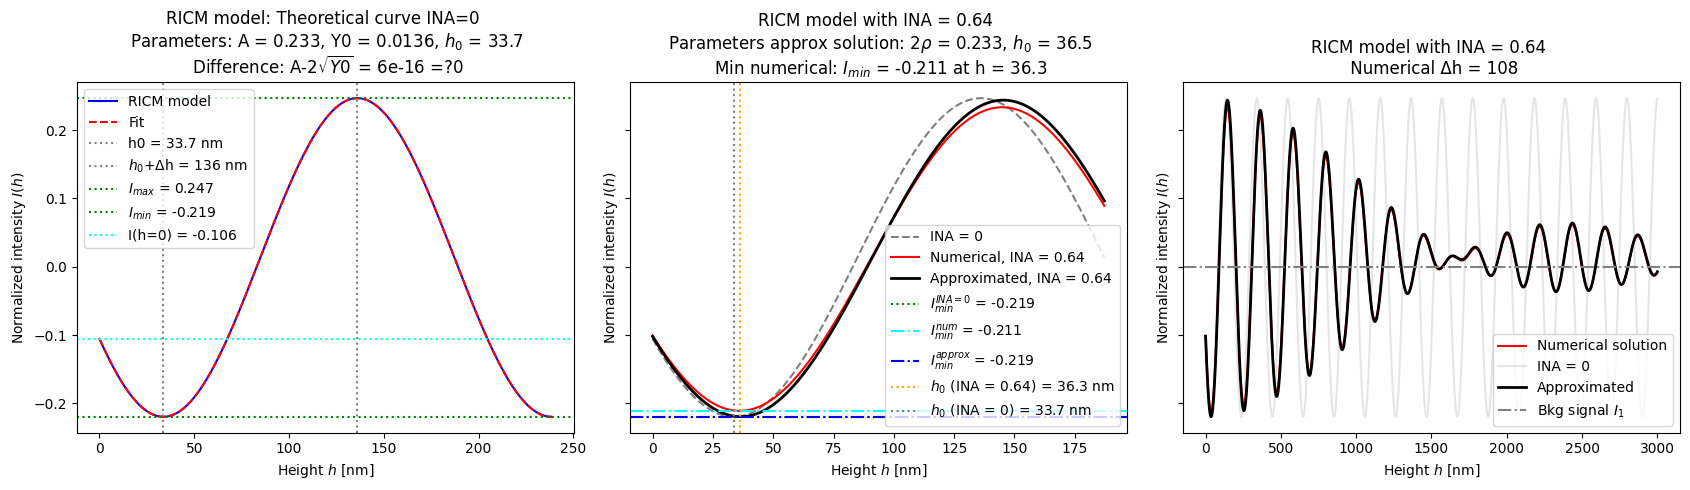

In [10]:
# ============================================================================
#           INTENSITY I(h) CURVE
# ============================================================================

""" 
Plot of the expected intensity I(h) curve for the RICM model with the parameters defined above
without and considering the illumination numerical aperture (INA). The curve is normalized with respect to the back reflected light from the glass/SLB interface.
The I(h) curve with INA is implemented only for a 3 reflection system.  
"""

# --- 0) General parameters
Delta_h = LAMBDA_LIGHT/(4*n_1)   # distance between a minimum and a maximum
h_min , h_max = -50  , 150   
h_range = np.linspace(h_min, h_max, 500)    # the fitting range is exactly confined into only ONE branch

# --- 1) I(h) curve with INA = 0 (not considering the illumination numerical aperture)
def I_INA_0(h, A, Y0, h0):
    return Y0 - A * np.cos(4 * np.pi * n_1 * (h - h0) / LAMBDA_LIGHT)

def I_INA_not_0(h, rho, h0):
    alpha = np.arcsin(ILLUMINATION_NUMERICAL_APERTURE / n_1)
    sinSquare = np.sin(alpha / 2) ** 2
    k = 2 * np.pi * n_1 / LAMBDA_LIGHT
    y = 2 * k * h * sinSquare
    return rho**2 - 2*rho*np.sinc(y / np.pi) * np.cos(2*k*(1-sinSquare)*(h - h0) ) 

RICM_mapping = RICM.Height_map( n_inner= n_3, n_outer = n_1, l = LAMBDA_LIGHT, p = 0)   # access the class Height_map
popt, pcov = optimize.curve_fit(I_INA_0 , h_range, RICM_mapping.R_norm(h_range)) # fit R_norm in the range h to get Y0_parameter,A,h0
A_parameter , Y0_parameter, h0 = popt
print(f'Parameters height fit: A = {A_parameter:.3g}, Y0 = {Y0_parameter:.3g}, h0 = {h0:.3g}')

# - PLOTs
fig, ax = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

h_range = np.linspace(0, h0+2*Delta_h, 500)
ax[0].plot(h_range, RICM_mapping.R_norm(h_range), label='RICM model', color='blue')
ax[0].plot(h_range, I_INA_0(h_range, *popt), label='Fit', color='red', linestyle='--')
ax[0].axvline(h0, color='gray', linestyle=':', label=f'h0 = {h0:.3g} nm')   # check: minimum should sit here
ax[0].axvline(h0+Delta_h, color='gray', linestyle=':', label=f'$h_0$+Δh = {h0+Delta_h:.3g} nm')   # check: minimum should sit here
ax[0].axhline(Y0_parameter + A_parameter, color='green', linestyle=':', label=f'$I_{{max}}$ = {Y0_parameter+A_parameter:.3g}')
ax[0].axhline(Y0_parameter - A_parameter, color='green', linestyle=':', label=f'$I_{{min}}$ = {Y0_parameter-A_parameter:.3g}')
ax[0].axhline(I_INA_0(0, *popt), color='cyan', linestyle=':', label=f'I(h=0) = {I_INA_0(0, *popt):.3g}')
ax[0].set_title(f'RICM model: Theoretical curve INA=0 \n Parameters: A = {A_parameter:.3g}, Y0 = {Y0_parameter:.3g}, $h_0$ = {h0:.3g} \n Difference: A-2$\sqrt{{Y0}}$ = {A_parameter-2*np.sqrt(Y0_parameter):.1g} =?0')
ax[0].set_xlabel('Height $h$ [nm]'); ax[0].set_ylabel('Normalized intensity $I(h)$')
ax[0].legend()

# --- 2) I(h) curve with INA != 0 (considering the illumination numerical aperture)
h_range_numerical = np.linspace(0, h0+1.5*Delta_h, 300)
I_norm_INA = I_norm_numeric(h_range_numerical, lam=LAMBDA_LIGHT, n0=n_0, n_w= 1.333, n_outer=n_1, n_membrane=n_2, n_inner=n_3, d_h2o = WATER_LAYER_THICKNESS,
                            d=MEMBRANE_THICKNESS, INA=ILLUMINATION_NUMERICAL_APERTURE, how_many_reflections = HOW_MANY_REFLECTIONS, angular=True, N = 1000)
I_norm_INA_approximated = I_norm_numeric(h_range_numerical, lam=LAMBDA_LIGHT, n0=n_0, n_w= 1.333, n_outer=n_1, n_membrane=n_2, n_inner=n_3, d_h2o = WATER_LAYER_THICKNESS,
                            d=MEMBRANE_THICKNESS, INA=ILLUMINATION_NUMERICAL_APERTURE, how_many_reflections = HOW_MANY_REFLECTIONS, angular=False, N = 1000)
popt, pcov = optimize.curve_fit(I_INA_not_0 , h_range_numerical, I_norm_INA_approximated ) # fit R_norm in the range h 
rho_INA , h0_INA = popt

ax[1].plot(h_range_numerical, RICM_mapping.R_norm(h_range_numerical), label='INA = 0', color='gray',  linestyle='--')
ax[1].plot(h_range_numerical, I_norm_INA, label=f'Numerical, INA = {ILLUMINATION_NUMERICAL_APERTURE}', color='red',  linestyle='-' )
ax[1].plot(h_range_numerical, I_norm_INA_approximated, 'k', lw=2, label=f'Approximated, INA = {ILLUMINATION_NUMERICAL_APERTURE}')
ax[1].axhline(Y0_parameter - A_parameter, color='green', linestyle=':', label=f'$I^{{INA=0}}_{{min}}$ = {Y0_parameter-A_parameter:.3g}')
ax[1].axhline(np.min(I_norm_INA), color='cyan', linestyle='-.', label=f'$I^{{num}}_{{min}}$ = {np.min(I_norm_INA):.3g}')
ax[1].axhline(np.min(I_norm_INA_approximated), color='blue', linestyle='-.', label=f'$I^{{approx}}_{{min}}$ = {np.min(I_norm_INA_approximated):.3g}')
h0_numerical = int(np.min( [i for i, j in enumerate(I_norm_INA) if j == np.min(I_norm_INA)]))*np.diff(h_range_numerical)[0]
h_Max_position = int(np.min( [i for i, j in enumerate(I_norm_INA) if j == np.max(I_norm_INA)]))*np.diff(h_range_numerical)[0]
Delta_h_numerical = h_Max_position-h0_numerical
ax[1].axvline(h0_numerical, color='orange', linestyle=':', label=f'$h_0$ (INA = {ILLUMINATION_NUMERICAL_APERTURE}) = {h0_numerical:.3g} nm')   # check: minimum should sit here
ax[1].axvline(h0, color='gray', linestyle=':', label=f'$h_0$ (INA = 0) = {h0:.3g} nm')   # check: minimum should sit here
ax[1].set_title(f'RICM model with INA = {ILLUMINATION_NUMERICAL_APERTURE} \n Parameters approx solution:'+r' $2\rho$'+f' = {2*rho_INA:.3g}, $h_0$ = {h0_INA:.3g} \n Min numerical: $I_{{min}}$ = {np.min(I_norm_INA):.3g} at h = {h0_numerical :.3g}')
ax[1].set_xlabel('Height $h$ [nm]'); ax[1].set_ylabel('Normalized intensity $I(h)$')
ax[1].legend()

h_range_numerical = np.linspace(0, 3000, 3000)
I_norm_INA = I_norm_numeric(h_range_numerical, lam=LAMBDA_LIGHT, n0=n_0, n_w= 1.333, n_outer=n_1, n_membrane=n_2, n_inner=n_3, d_h2o = WATER_LAYER_THICKNESS,
                            d=MEMBRANE_THICKNESS, INA=ILLUMINATION_NUMERICAL_APERTURE, how_many_reflections = HOW_MANY_REFLECTIONS, angular=True, N = 1000)
I_norm_INA_approximated = I_norm_numeric(h_range_numerical, lam=LAMBDA_LIGHT, n0=n_0, n_w= 1.333, n_outer=n_1, n_membrane=n_2, n_inner=n_3, d_h2o = WATER_LAYER_THICKNESS,
                            d=MEMBRANE_THICKNESS, INA=ILLUMINATION_NUMERICAL_APERTURE, how_many_reflections = HOW_MANY_REFLECTIONS, angular=False, N = 1000)
ax[2].plot(h_range_numerical, I_norm_INA, label=f'Numerical solution', color='red',  linestyle='-' )
ax[2].plot(h_range_numerical, RICM_mapping.R_norm(h_range_numerical), label='INA = 0', color='gray', alpha = 0.2,  linestyle='-')
ax[2].plot(h_range_numerical, I_norm_INA_approximated, 'k', lw=2, label=f'Approximated')
ax[2].axhline(0, color='gray', linestyle='-.', label=f'Bkg signal $I_1$')
ax[2].set_title(f'RICM model with INA = {ILLUMINATION_NUMERICAL_APERTURE} \n Numerical Δh = {Delta_h_numerical:.3g}')
ax[2].set_xlabel('Height $h$ [nm]'); ax[2].set_ylabel('Normalized intensity $I(h)$')
ax[2].legend()
plt.tight_layout()

### IMAGE PREPARATION

#### Image preparation: subtract dark current bkg and select the interesting zone

In [11]:
# ============================================================================
#           PATHS AND NAMES
# ============================================================================

Directory_with_the_images_to_be_analyzed = r'C:\Users\nicol\Desktop\ch4\Ecad_NV'    # r"E:\RICM\2026-07-02\ch4\Ecad_NV"
NAME_FILE = 'adhesion_1.czi'
save_results_directory = r'C:\Users\nicol\Desktop\NICOLAS\Results\Erase_ME'   # REMEMEBER ME!!!!!!
ANOTHER_GUV_IN_THE_SAME_IMAGE = ''   # add here any extension to the name, for example if you are analyzing the 2nd GUV of the image: + '_2ndGV'
bkg_path = os.path.join(r"E:\RICM\2026-07-08", 'dark_current-09.czi')   # (directory, name of the bkg image) -> If you want to use a dark current bkg instead of the manual bkg subtraction

# -----------------------------------------------------------------------------
image_path = os.path.join(Directory_with_the_images_to_be_analyzed, NAME_FILE)
file_name  = Path(image_path).stem + ANOTHER_GUV_IN_THE_SAME_IMAGE
os.makedirs(save_results_directory, exist_ok=True)

In [12]:
# ============================================================================
#           HAVE YOU MODIFIED THE CODE ==> TEST THE OUTCOMES!
# ============================================================================

DO_YOU_WANT_TO_TEST_THE_CODE = False
TEST_IMAGE_NUMBER            = 1                   

if DO_YOU_WANT_TO_TEST_THE_CODE:
    Directory_with_the_test_images = r"C:\Users\nicol\Desktop\NICOLAS\RICM_Test_images"
    #  create test images 
    # image_path = os.path.join(DO_YOU_WANT_TO_TEST_THE_CODE,  .... )
    file_name  = 'test_image_N' + str(TEST_IMAGE_NUMBER)

In [ ]:
# Next cell functions
import czifile

def read_stack(path):
    ext = Path(path).suffix.lower()
    if ext == '.czi':
        return np.squeeze(czifile.imread(path))
    elif ext in ('.tif', '.tiff'):
        img = Image.open(path)
        frames = []
        try:
            while True:
                frames.append(np.array(img.copy()))
                img.seek(img.tell() + 1)
        except EOFError:
            pass
        return np.array(frames)
    else:
        raise ValueError(f'Unsupported file format: {ext}')

def merge_and_average_N_images(ricm_imges, show = False, Do_you_want_an_average = True):
    if Do_you_want_an_average:
        N_img, img_width, img_height = ricm_imges.shape[:3]
        data_stack = np.array(ricm_imges) 
        # Calculate the mean across the image index axis
        ricm_img = np.mean(data_stack, axis=0).round().astype(np.uint16)
        print(f'Average over N = {N_img} images')
        if show: 
            plt.imshow(ricm_img, cmap='gray')
            plt.colorbar()
    else: ricm_img = ricm_imges
    return ricm_img

 
def subtract_bkg_from_corners(ricm_img, bkg_img, x1 , x2 , y1 , y2, show = True, Use_dark_currents_bkg = False):
    # Identify the bkg from the corners of the image and subtract its average

    img_width, img_height = ricm_img.shape[:2]
    bkg_regions = [
        (0, y1, 0, x1),       # Top-left
        (0, y1, x2, img_width), # Top-right
        (y2, img_height, 0, x1), # Bottom-left
        (y2, img_height, x2, img_width) # Bottom-right
    ]
    bkg_means = []

    if show: 
        plt.figure(figsize=(17,3), dpi = 200)
        plt.subplot(142)
        plt.xlabel('Bkg intensity') ; 
        plt.title('Distributions', fontsize='x-large')

    for i, (ys, ye, xs, xe) in enumerate(bkg_regions):
        region_data = ricm_img[ys:ye, xs:xe]
        if show: plt.hist(region_data.ravel(), alpha = i/(i+2) )
        avg_intensity = np.mean(region_data)
        bkg_means.append(avg_intensity)
        if show:                            
            print("Background Evaluation:")
            print(f"Region {i+1}: Mean Intensity = {avg_intensity:.2f}")                                                                

    total_bkg_avg = np.mean(bkg_means)

    if show:
        print(f"\n Average Background: {total_bkg_avg:.2f}")
        plt.vlines(total_bkg_avg,*plt.gca().get_ylim() , label = f'mean = {total_bkg_avg:.0f}' , color= 'red', linestyle = '--') ; plt.legend(loc='best')
        plt.subplot(141)
        plt.imshow(ricm_img, cmap="gray")
        plt.xlabel(f'$x_1 = {x1}, x_2 = {x2} $') ; plt.ylabel(f'$y_1 = {y1}, y_2 = {y2} $')
        plt.title('Select the background', fontsize='x-large')
        plt.xlim(0, img_width) ; plt.ylim(img_height, 0) 
        plt.hlines([y1, y2], 0, img_width, color='red', linestyle='--')
        plt.vlines([x1, x2], 0, img_height, color='blue', linestyle='--')
        plt.colorbar() 

        plt.subplot(143)
        plt.imshow(ricm_img - total_bkg_avg, cmap="gray")
        plt.title('Bkg corrected image', fontsize='x-large')
        plt.colorbar()
        cv2.waitKey(0)  
    # bkg from dark currents
    if bkg_img is not None:
        dark_currents_bkg = np.mean(bkg_img)
        if show: 
            print(f'Average bkg due to dark currents = {dark_currents_bkg:.2f}')
            plt.subplot(144)
            plt.hist(bkg_img.ravel(), alpha = 0.7)
            plt.vlines(dark_currents_bkg, *plt.gca().get_ylim(), label = f'mean = {dark_currents_bkg:.0f}', color= 'red', linestyle = '--')
            plt.title('Dark currents bkg', fontsize='x-large') ; plt.legend(loc='best')
    if Use_dark_currents_bkg:
        total_bkg_avg = dark_currents_bkg
        if show: print(f'Using dark currents bkg = {total_bkg_avg:.2f}')
        
    return ricm_img - total_bkg_avg , total_bkg_avg

def crop_image( ricm_img, x_start , x_end , y_start , y_end  , show = True):
    
    img_width, img_height = ricm_img.shape[:2]
    crop_img = ricm_img[y_start:y_end, x_start:x_end]

    if show:
        plt.figure(figsize=(12,5), dpi = 200)
        plt.subplot(121)
        plt.imshow(ricm_img, cmap="gray")
        plt.xlabel(f'$x_1 = {x_start}, x_2 = {x_end} $') ; plt.ylabel(f'$y_1 = {y_start}, y_2 = {y_end} $')
        plt.title(f'Selected interesting zone', fontsize='x-large')
        plt.hlines(y_start, 0 , img_width, colors='red', linestyles='--' ) ; plt.hlines(y_end, 0 , img_width, colors='red', linestyles='--' )
        plt.vlines(x_start, 0 , img_height, colors='blue', linestyles='--' ) ; plt.vlines(x_end, 0 , img_height, colors='blue', linestyles='--' )
        plt.colorbar()

        plt.subplot(122)
        plt.imshow(crop_img, cmap="gray")
        plt.title('Cropped', fontsize='x-large')
        plt.colorbar()
        cv2.waitKey(0)  
    return crop_img

Average over N = 100 images
Image stack shape: (100, 512, 512)
Background shape:  (512, 512)
Background Evaluation:
Region 1: Mean Intensity = nan
Background Evaluation:
Region 2: Mean Intensity = nan
Background Evaluation:
Region 3: Mean Intensity = nan
Background Evaluation:
Region 4: Mean Intensity = nan

 Average Background: nan


c:\Users\nicol\Anaconda\envs\first_env\Lib\site-packages\numpy\_core\fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\nicol\Anaconda\envs\first_env\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Average bkg due to dark currents = 100.00
Using dark currents bkg = 100.00


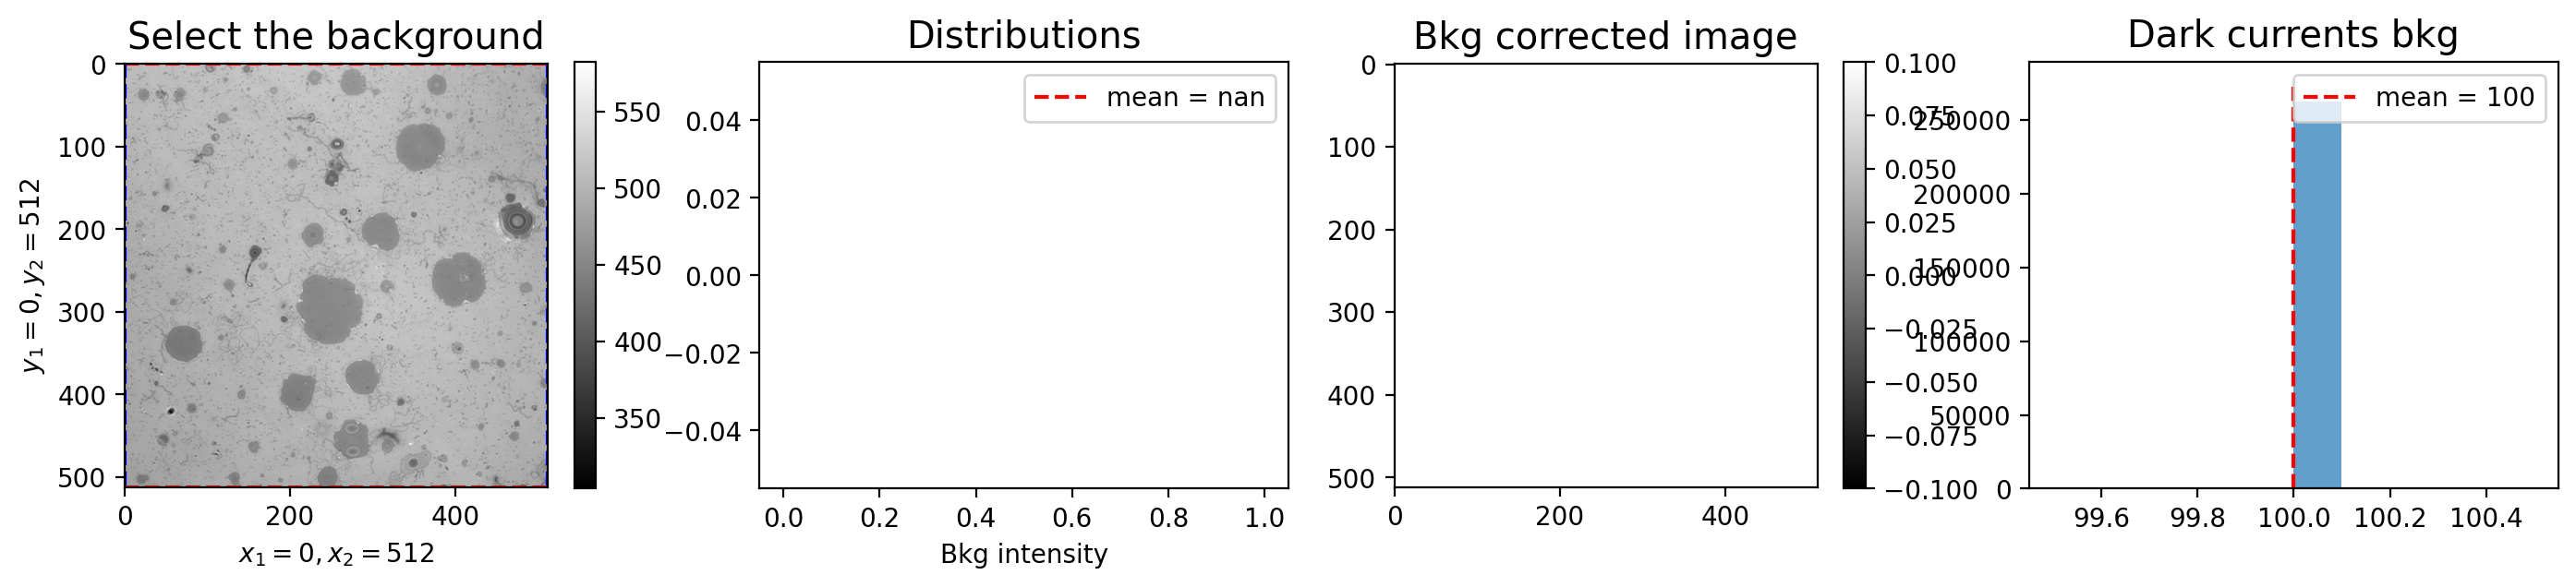

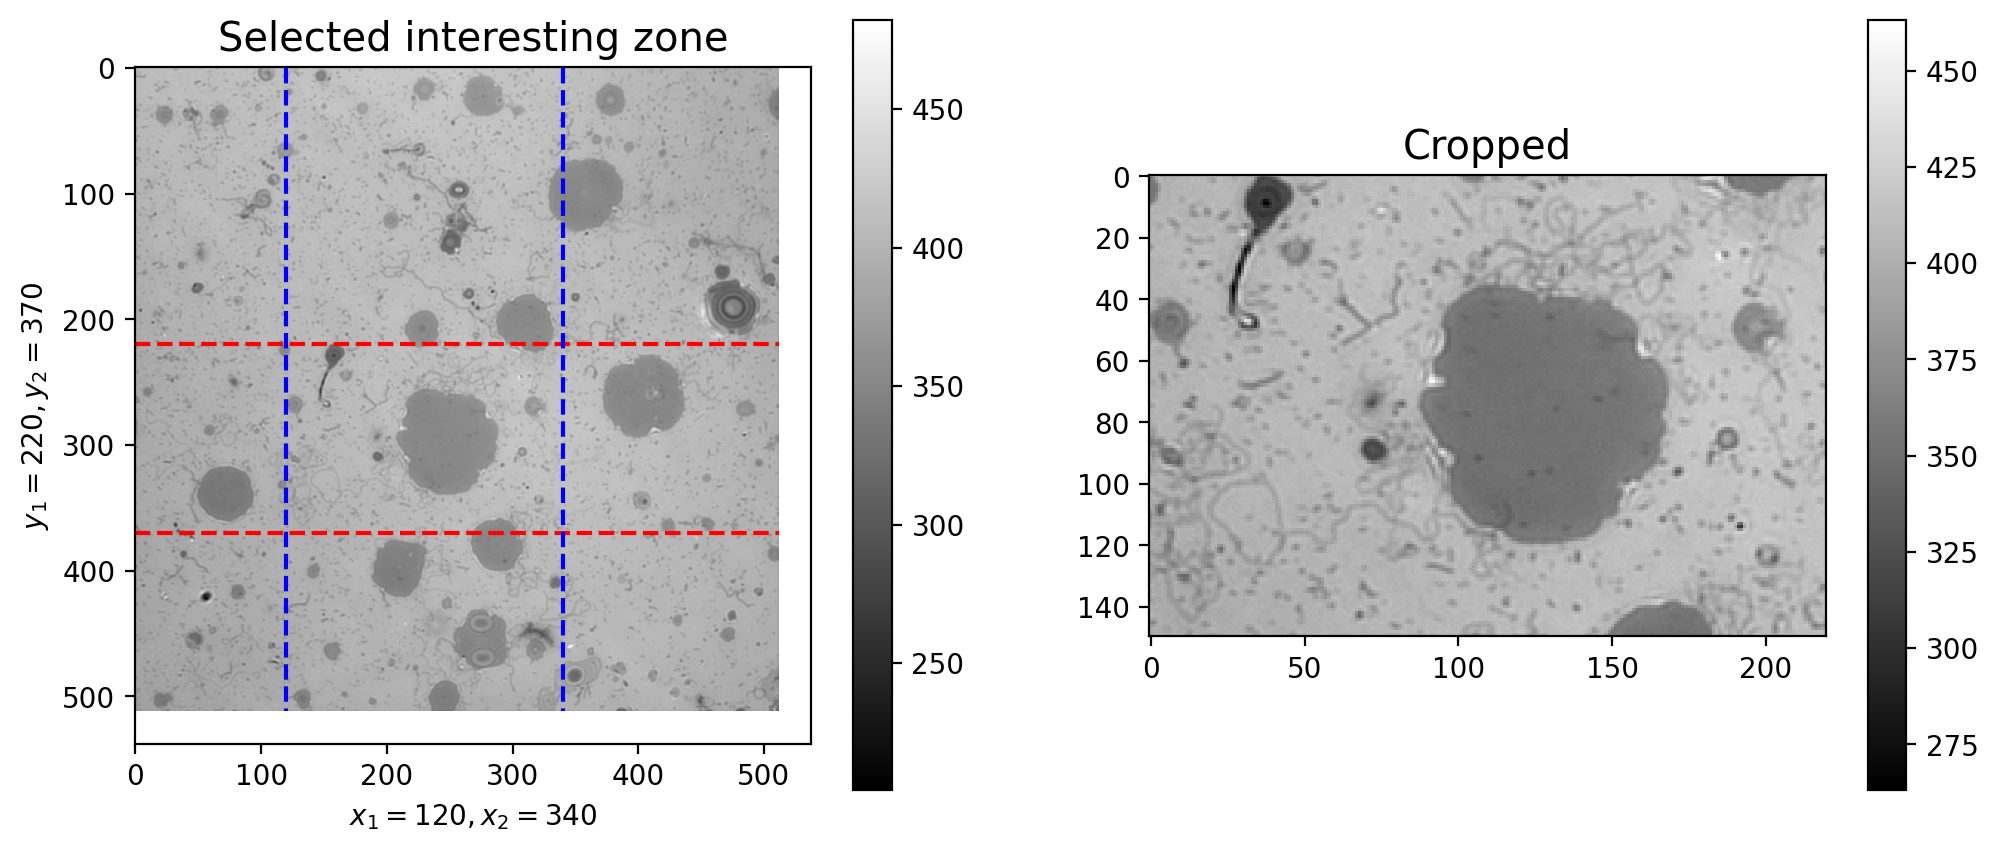

In [14]:
# ============================================================================
#           IMNAGES PREPARATIONS: DARK CURRENT SUBTRACTION AND CROP
# ============================================================================

# Parameters to TUNE: 
X_AXIS_EXTENSION, Y_AXIS_EXTENSION = 0 , 0            # Select it to properly evaluate the bkg at the corners of the image (where you see the Field Diaphragm) in a symmetrical way
X_START_CROP , X_END_CROP          = 120, 340         # CROP LIMITS: select the interesting region where the vesicle is
Y_START_CROP , Y_END_CROP          = 220, 370
USE_DARK_CURRENTS_BKG_IMG          = True             # Do you want to use the dark currents bkg instead of the manual bkg subtraction? (True or False)
SAVE_BKG_IMG                       = False            # Do you want to save the dark current subtracted image? (True or False)
SAVE_CROPPED_IMG                   = False            # Do you want to save the cropped image? (True or False)


# ── Read czi or tif stack ─────────────────────────────────────────────────────
RICM_imgs_I_raws = read_stack(image_path)   # read the image stack depending on the extension of the file (czi or tif)
RICM_average_img_I_raw = merge_and_average_N_images(RICM_imgs_I_raws)  # do an average of all the images to get a resulting image 

# bkg_img    = read_stack(bkg_path)
bkg_img = np.full_like(RICM_average_img_I_raw, 100)  # REPLACE WITH CORRECT LINE!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!11
print(f'Image stack shape: {RICM_imgs_I_raws.shape}')
print(f'Background shape:  {bkg_img.shape}')

# 1)  --- Subtract the bkg from the corners or from the dark currents signal
x_bkg_1 , x_bkg_2 = X_AXIS_EXTENSION, RICM_average_img_I_raw.shape[0] - X_AXIS_EXTENSION 
y_bkg_1 , y_bkg_2 = Y_AXIS_EXTENSION, RICM_average_img_I_raw.shape[1] - Y_AXIS_EXTENSION 
img_bkg_subtracted, Dark_currents_avg_bkg  = subtract_bkg_from_corners(RICM_average_img_I_raw, bkg_img ,  x1 = x_bkg_1 , x2 = x_bkg_2, y1 = y_bkg_1, y2 = y_bkg_2, 
                                                                       show = True, Use_dark_currents_bkg = USE_DARK_CURRENTS_BKG_IMG)
if SAVE_BKG_IMG: plt.savefig( save_results_directory + r'\ '+ file_name + r'_1_Bkg_Processing.png' , dpi = 300, bbox_inches='tight')  

# 2) --- Select a vesicle
cropped_image = crop_image( img_bkg_subtracted,  x_start = X_START_CROP , x_end = X_END_CROP, y_start = Y_START_CROP , y_end = Y_END_CROP , show = True)
plt.savefig( save_results_directory + r'\ '+ file_name + r'_2_Vesicle.png' , dpi = 300, bbox_inches='tight')  


### RICM ANALYSIS

In [15]:
# Funcion for the next cells

def display_image( image , img_title, cmap_img, color_bar_label = '', axis = 'off'):
    plt.axis(axis)
    plt.title(img_title)
    plt.imshow(image , cmap = cmap_img )
    plt.colorbar(label = color_bar_label)

#### Identification of the Adhesion zone

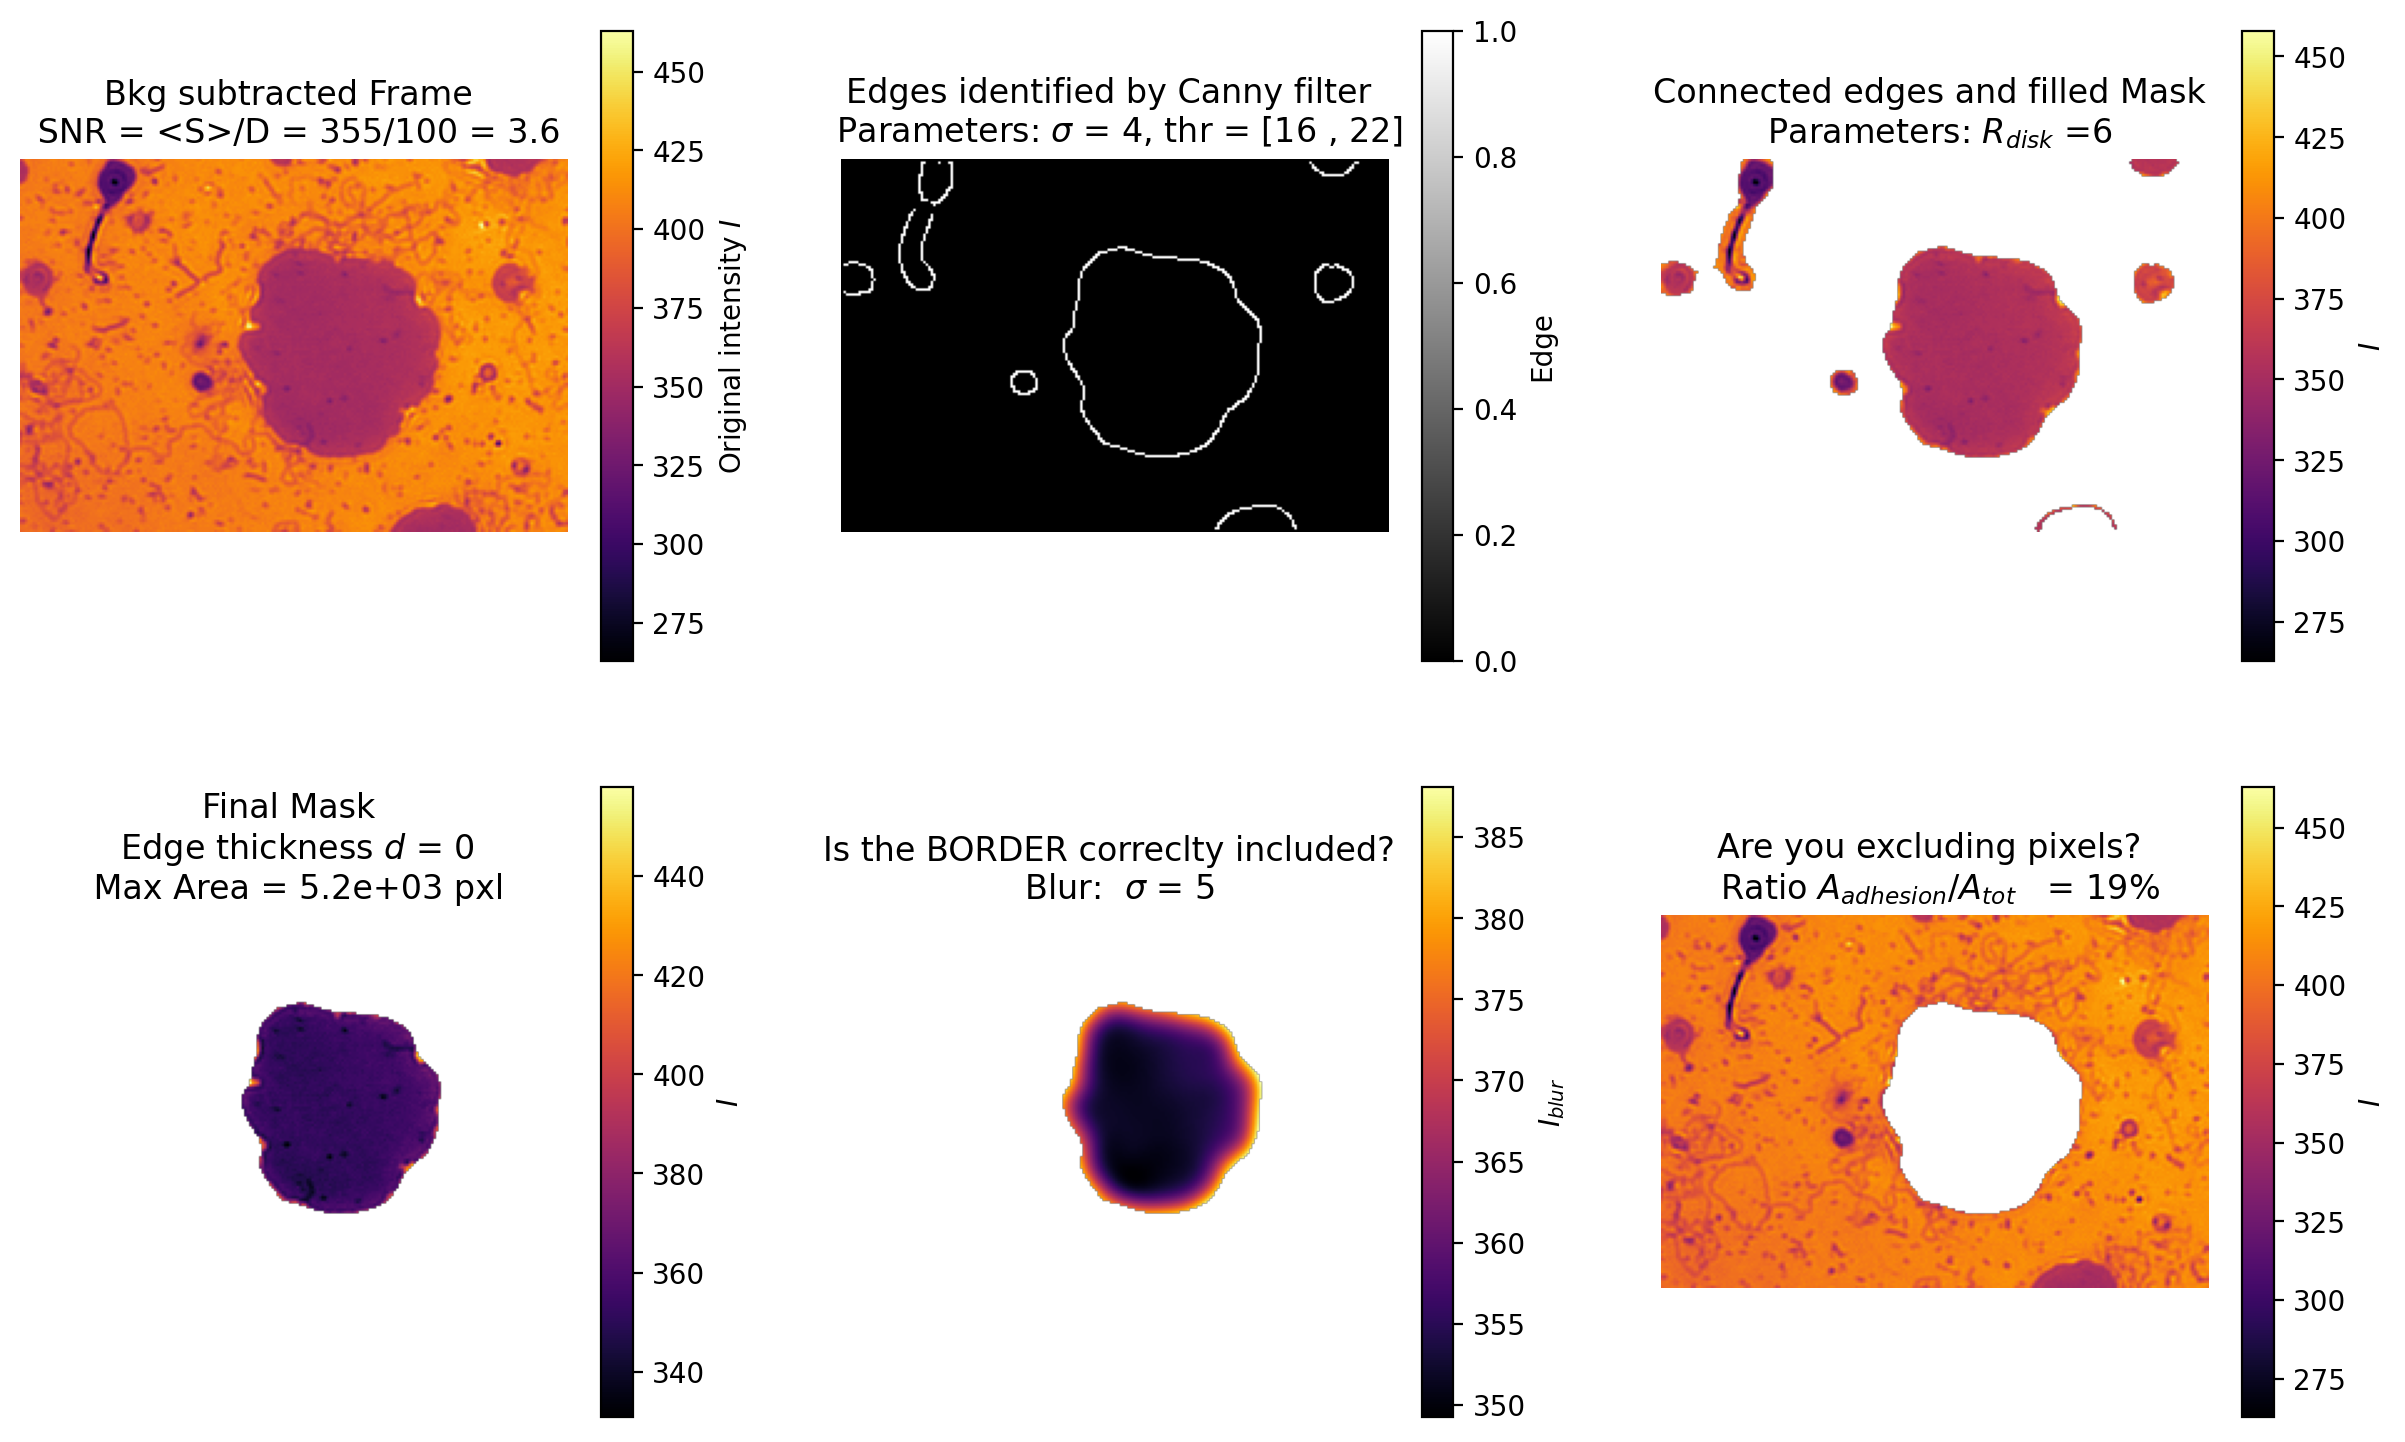

In [28]:
from scipy.ndimage import gaussian_filter
from skimage.morphology import closing, disk, dilation
from skimage.measure import label, regionprops
from scipy.ndimage import binary_fill_holes
from skimage.feature import canny
from scipy.ndimage import sobel

# ============================================================================
#           ADHESION ZONE IDENTIFICATION 
# ============================================================================

"""
By selecting appropriate values of the parameters for the Canny algorithm, we try to isolate the adhering zone from the background
RETURN:   adhesion_zone_img 
"""

# PARAMETERS to tune for the identifiaction
SIGMA_GUASSIAN_CANNY  = 4    # px         # CANNY Edges alorithm: blur radius; select SIGMA > 2 and SIGMA > 10
LOW_THR_CANNY         = 16    # I_blur     # CANNY Edges alorithm: TUNE THESE PARAMETERS; lower threshold: every pixel from the blurred image with I<low_th is discarded
HIGH_THR_CANNY        = 22   # I_blur     # CANNY Edges alorithm: TUNE THESE PARAMETERS; higher threshold: every pixel from the blurred image with I>high_th is keeped and low_th<I<high_th is kept only if next to a I>high_th pixel
CLOSE_EDGES_DISK      = 6    # px         # Disk radius for closing the gaps in the mask; R > 10
EDGE_THICKNESS        = 0    # px         # To consider the thickness of the edges founded by the Canny algorithm; d > 3
SIGMA_GUASSIAN_PLOT   = 5    # px         # Controls the BLUR strength for the final plot on a non processed image. You can choose SIGMA_GUASSIAN_CANNY by looking at this plotted image
SAVE_ADHESION_IMG     = False             # Do you want to save the adhesion zone identification image? (True or False)

if SIGMA_GUASSIAN_CANNY > 1 :
    img = cropped_image
    
    # --- 1) Apply the Canny edge detection algorithm: first perform a gaussian filter, then find edges by applying a low-high threshold
    Canny_edges = canny(img, sigma = SIGMA_GUASSIAN_CANNY , 
                        low_threshold= LOW_THR_CANNY, 
                        high_threshold= HIGH_THR_CANNY)

    # --- 2) Obtain the Mask: close the Canny edges + fill them + consider the edge thickness   
    edges_closed = closing(Canny_edges, footprint=disk(CLOSE_EDGES_DISK)) # bridges gaps in the Canny edge line, turning a broken contour into a closed ring
    rim_thick = dilation(edges_closed, footprint=disk(EDGE_THICKNESS))  # Add the edge thickness # adjust radius to match rim thickness
    mask_filled = binary_fill_holes(edges_closed | rim_thick  ) # fill everything inside
    img_filled = img.copy() ; img_filled[~mask_filled] = np.nan

    # Keep only the largest connected region
    labeled = label(mask_filled)
    regions = regionprops(labeled)
    largest_region = max(regions, key=lambda r: r.area)
    mask_filled_largest_region = labeled == largest_region.label

    Final_Mask = mask_filled_largest_region        # final mask
    area_adhesion_zone = np.sum(Final_Mask)
    ratio_adhesionZone_to_TotalArea = area_adhesion_zone/np.sum(~Final_Mask)

    adhesion_zone_img = img.copy() ; adhesion_zone_img[ ~Final_Mask] = np.nan

    # --- 3) Display it better to see if the BORDER of the fluctuation zone is correctly included
    img_smooth = gaussian_filter(img, sigma= SIGMA_GUASSIAN_PLOT) ; img_smooth[~Final_Mask] = np.nan
    img_outside_mask = img.copy() ; img_outside_mask[ Final_Mask] = np.nan

    imgs_to_plot = [img, Canny_edges, img_filled, adhesion_zone_img , img_smooth , img_outside_mask]
    imgs_to_plot_title = [f'Bkg subtracted Frame \n SNR = <S>/D = {np.nanmean(img[Final_Mask]):.3g}/{Dark_currents_avg_bkg:.3g} = {np.nanmean(img[Final_Mask])/Dark_currents_avg_bkg:.2g}',  
                        f'Edges identified by Canny filter \n Parameters:'+r' $\sigma$'+f' = {SIGMA_GUASSIAN_CANNY}, thr = [{LOW_THR_CANNY} , {HIGH_THR_CANNY}]' ,
                        f'Connected edges and filled Mask \n Parameters:' + r' $R_{disk}$ ='+f'{CLOSE_EDGES_DISK}',
                        f'Final Mask \n Edge thickness $d$ = {EDGE_THICKNESS} \n Max ' + r'Area = ' + f'{area_adhesion_zone:.2g} pxl', 
                        f'Is the BORDER correclty included? \n Blur: '+r' $\sigma$'+f' = {SIGMA_GUASSIAN_PLOT}',
                        'Are you excluding pixels? \n Ratio $A_{adhesion}/A_{tot}$   = ' + f'{ratio_adhesionZone_to_TotalArea*100:.0f}%']
    color_bars = ['inferno' , 'gray', 'inferno', 'inferno', 'inferno', 'inferno']
    color_bar_labels = [ r'Original intensity $I$', 'Edge' , r'$I$', r'$I$' , r'$I_{blur}$' ,r'$I$' ]

    fig = plt.figure(figsize = (15,9) , dpi = 200 )
    for j, plot_img in enumerate(imgs_to_plot):
        plt.subplot( int( '23'+ str(j+1)) )
        display_image(  plot_img , axis = 'off', img_title = imgs_to_plot_title[j] , cmap_img = color_bars[j], color_bar_label = color_bar_labels[j] )
    if SAVE_ADHESION_IMG: plt.savefig( save_results_directory + r'\ ' + file_name + r'_3_Adhezion_zone.png' , dpi = 300, bbox_inches='tight')  

#### Images normalization: preparing for intensity-height association

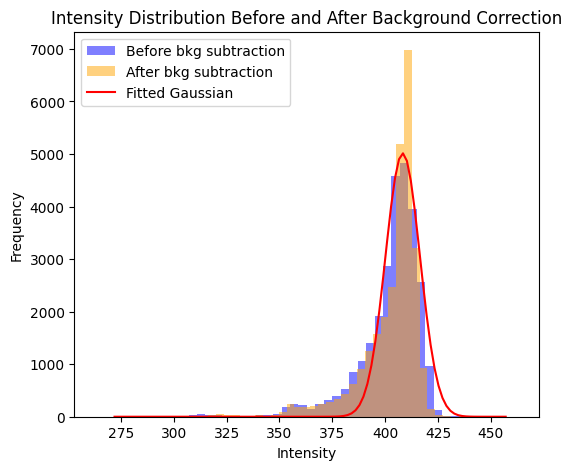

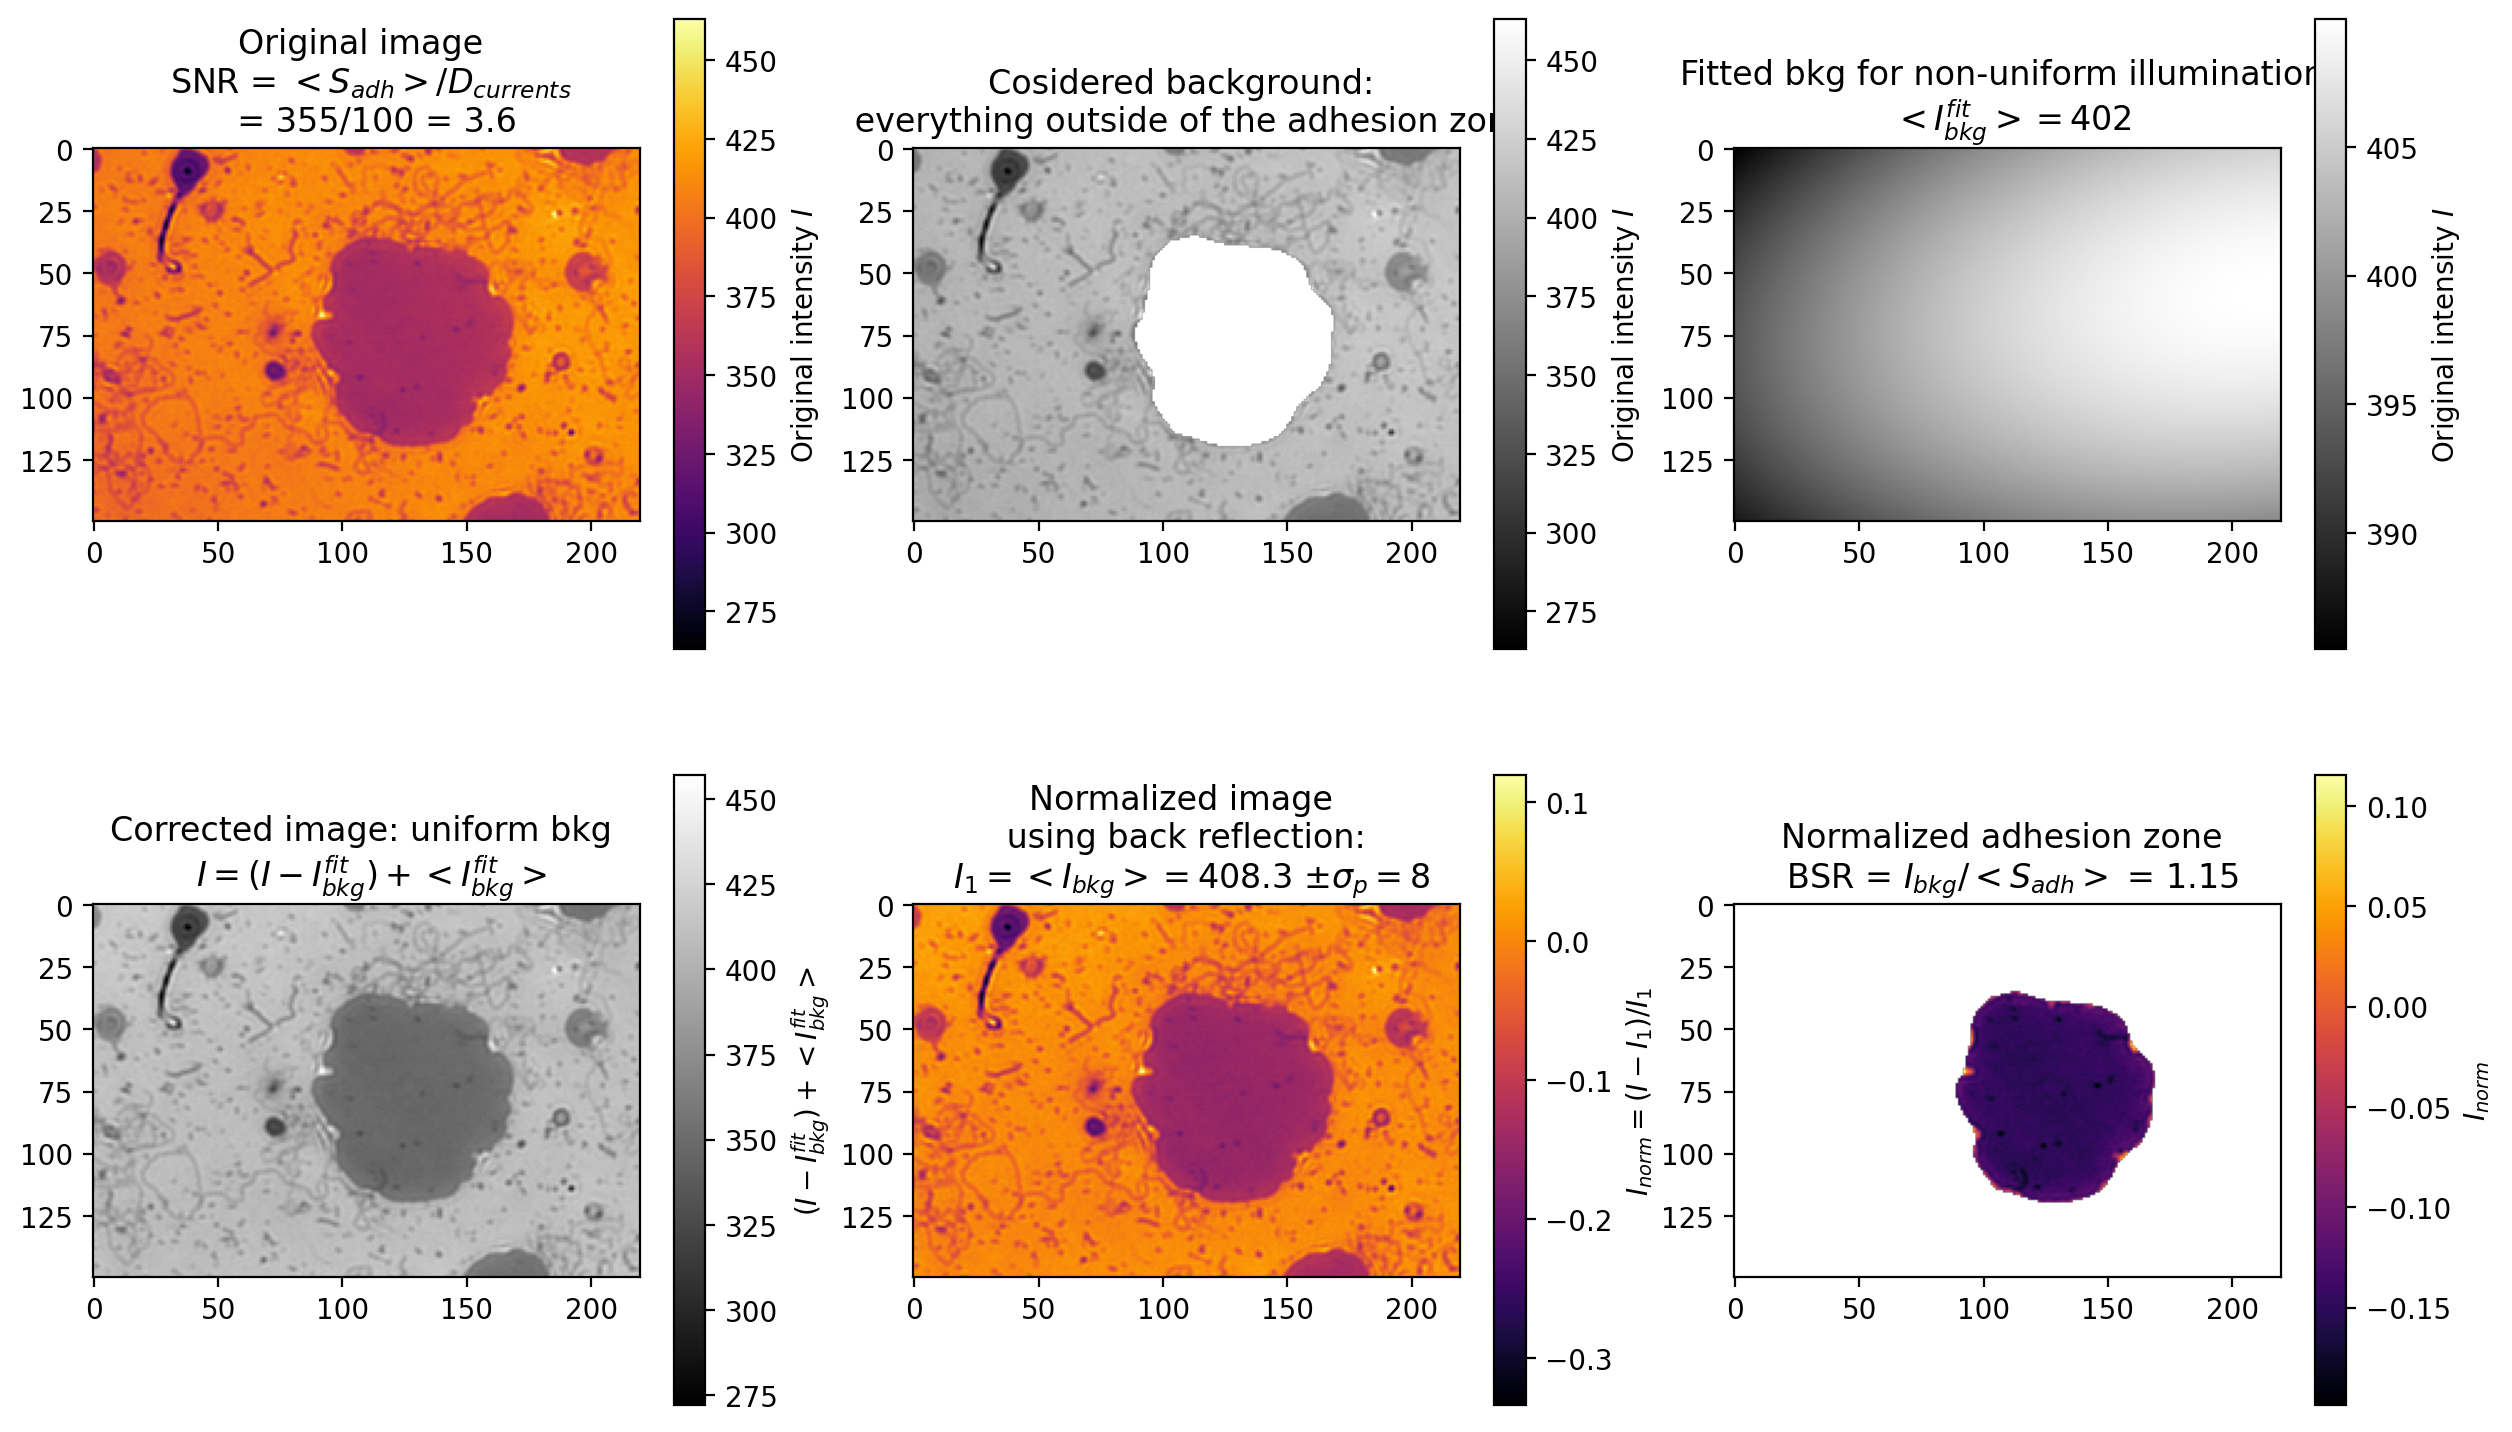

In [33]:

# ============================================================================
#           NORMALIZED IMAGES AND RICM PRE-ANALYSIS
# ============================================================================

"""
Obtain the normalized image with respect to back scattered light from the slid/SLB.
Adapted from Ahmed's code
KEY PRINCIPLES: consider everything outside the adhesion zone as I_0. First perform a fit to consider non-uniform illumination,
                then work with the uniform value of I_0. Normalization: (I_I_0)/I_0
RETURN: normalized_img                      -> full normalized image
        normalized_fluctuation_zone_img     -> normalized adhesion zone image only
        bkg_corrected_NotNorm_img           -> image before being normalized, i.e. bkg subtracted and corrected to non-uniform illumination
        average_backreflected_light_I_1     -> backreflected light I_1
"""


SAVE_NORMALIZATION_PROCEDURE    = False             # Do you want to save the normalization procedure? (True or False)
SAVE_NORMALIZED_IMG             = False              # Do you want to save the normalized image in tif format? (True or False)

img = cropped_image
average_backreflected_light_I_1 = []

# --- 1) Get the mask from the adhesion zone
adhesion_zone_mask = ~np.isnan(adhesion_zone_img)
    
# --- 2) Fit the background with a 2nd order polynomium
background_mask = np.isnan(adhesion_zone_img) # Background = pixels where the adhesion-zone image is NaN
x, y = np.nonzero(background_mask)           # coordinates of the background pixels
data = np.column_stack((x, y, img[x, y]))    # (N, 3) array: x, y, intensity

# Reconstruct the 2D image
background_img = np.full(img.shape, np.nan)  # start with NaN everywhere
background_img[data[:, 0].astype(int), data[:, 1].astype(int)] = data[:, 2]

# best-fit: quadratic curve
A = np.c_[np.ones(data.shape[0]), data[:,:2], np.prod(data[:,:2], axis=1), data[:,:2]**2] # in each column there is an element like: [1, x, y, x*y, x*x, y*y]
C,_,_,_ = linalg.lstsq(A, data[:,2]) # x = linalg.lstsq(A,b) Return x the least-squares solution to a linear matrix equation: it provides the vector x that solves A@x = b. # intensity = data[:,2] equal to {0,1}

reconstructed_bkg = np.ones(img.shape) # Copy the original img with only ones
for X in range(img.shape[0]): # Fill the background with the values came from the fitting, including the adhesion zone
    for Y in range(img.shape[1]):
        reconstructed_bkg[X,Y] = C[0] + C[1]*X + C[2]*Y + C[3]*X*Y + C[4]*X*X + C[5]*Y*Y     # C is a 5 dim vector with the coefficients of the fit that better fit the background

# --- 3) Correcting the image by subtracting the background then adding it's average to each pixel
bkg_corrected_NotNorm_img = (img - reconstructed_bkg) + np.average(reconstructed_bkg)

# --- 4) Normalize the image by using the bkg signal 
corrected_background = bkg_corrected_NotNorm_img * (1 - adhesion_zone_mask )  # exlude the adhesion zone from the corrected img
histogram_bkg = corrected_background[corrected_background != 0].ravel()
avg_corrected_background, sigma_fit = Fit_Gaussian(corrected_background, normalized=True).hist_fitting() # Fit a Gaussian on the corrected background histogram then take it's mean

# --- 3.5) Plot an histogram of the intensity distribution before and after the background correction
plt.figure(figsize=(6,5), dpi = 100)
before_bkg_subtraction = img[background_mask].ravel()
after_bkg_subtraction = bkg_corrected_NotNorm_img[background_mask].ravel()
plt.hist(before_bkg_subtraction, bins=50, alpha=0.5, label='Before bkg subtraction', color='blue')
plt.hist(after_bkg_subtraction, bins=50, alpha=0.5, label='After bkg subtraction', color='orange')
#plot also the fitted gaussian of mean avg_corrected_background adn sigma sigma_fit
plt.plot(np.linspace(min(after_bkg_subtraction), max(after_bkg_subtraction), 100), norm.pdf(np.linspace(min(after_bkg_subtraction), max(after_bkg_subtraction), 100), avg_corrected_background, sigma_fit) * len(after_bkg_subtraction) * (max(after_bkg_subtraction) - min(after_bkg_subtraction)) / 50, color='red', label='Fitted Gaussian')
plt.title('Intensity Distribution Before and After Background Correction') ; plt.xlabel('Intensity') ; plt.ylabel('Frequency') ; plt.legend()

normalized_img = (bkg_corrected_NotNorm_img - avg_corrected_background) / avg_corrected_background    # I_n = (I - I_1)/I_1
average_backreflected_light_I_1.append([avg_corrected_background , sigma_fit , len(histogram_bkg)]) 
normalized_adhesion_zone_img = normalized_img.copy() ;  normalized_adhesion_zone_img[ ~adhesion_zone_mask] = np.nan

imgs_to_plot = [img, background_img, reconstructed_bkg, bkg_corrected_NotNorm_img, normalized_img, normalized_adhesion_zone_img ]
imgs_to_plot_title = [f'Original image \n SNR = $<S_{{adh}}>/D_{{currents}}$ \n  = {np.nanmean(img[Final_Mask]):.3g}/{Dark_currents_avg_bkg:.3g} = {np.nanmean(img[Final_Mask])/Dark_currents_avg_bkg:.2g}',  
                        f'Cosidered background: \n everything outside of the adhesion zone' ,
                        f'Fitted bkg for non-uniform illumination \n ' + r'$<I^{fit}_{bkg}> = $'+f'{np.average(reconstructed_bkg):.0f}',
                        f'Corrected image: uniform bkg \n ' + r'$I = (I - I^{fit}_{bkg}) + <I^{fit}_{bkg}>$', 
                        f'Normalized image \n using back reflection: \n '+r'$I_1 = <I_{bkg}> = $'+f'{avg_corrected_background:.1f}'+r' $\pm \sigma_p=$'+f'{sigma_fit:.1g}',
                        'Normalized adhesion zone \n BSR = $I_{{bkg}}/<S_{{adh}}> $ ' + f'= {avg_corrected_background/np.nanmean(img[Final_Mask]):.3g}']
color_bars = ['inferno' , 'gray', 'gray', 'gray', 'inferno', 'inferno']
color_bar_labels = [ r'Original intensity $I$',  r'Original intensity $I$' ,  r'Original intensity $I$',  r'$(I - I^{fit}_{bkg}) + <I^{fit}_{bkg}>$' , r'$I_{norm} = (I - I_{1})/I_1$' , r'$I_{norm}$']

fig = plt.figure(figsize = (15,9) , dpi = 200 )
for j, plot_img in enumerate(imgs_to_plot):
    plt.subplot( int( '23'+ str(j+1)) )
    display_image(  plot_img , axis = 'on', img_title = imgs_to_plot_title[j] , cmap_img = color_bars[j], color_bar_label = color_bar_labels[j] )

if SAVE_NORMALIZATION_PROCEDURE: plt.savefig( save_results_directory + r'\ ' + file_name + r'_4_Normalization.png' , dpi = 300, bbox_inches='tight') 
if SAVE_NORMALIZED_IMG: io.imsave( save_results_directory + r'\ ' + file_name + r'_Normalized_averaged_image.tif' , normalized_img.astype(np.float32) )

#### Height Analysis

In [18]:
# Functions for the next cells
def intensity_to_height_simple(I_norm, Y0, A, h0, branch):
    """
    INA = 0: analytic inversion of  I_norm = Y0 - A * cos(2k (h - h0)),  2k = 4 pi n_outer / lam,
    on the given branch. I_norm must already be inside [Y0 - A, Y0 + A] (see in_range_mask).
    For branch 0 the heights can be negative (h0 - Delta_h < h < h0).
    """
    two_k = 4 * np.pi * n_1 / LAMBDA_LIGHT
    c = np.clip((Y0 - np.asarray(I_norm, float)) / A, -1, 1)     # c = cos(2k (h - h0)); clip only removes rounding errors
    return h0 + (np.pi * branch - np.arccos((-1) ** branch * c)) / two_k


def build_lookup(h_min, h_max, n_points=500):
    """Calibration curve I_norm(h) on the known branch [h_min, h_max] (h_min < 0 for branch 0: negative heights are kept)."""
    h_b = np.linspace(h_min, h_max, n_points)
    I_b = I_norm_numeric(h_b, lam=LAMBDA_LIGHT, n0=n_0, n_w=1.333, n_outer=n_1, n_membrane=n_2, n_inner=n_3,
                         d_h2o=WATER_LAYER_THICKNESS, d=MEMBRANE_THICKNESS, INA=ILLUMINATION_NUMERICAL_APERTURE,
                         how_many_reflections=HOW_MANY_REFLECTIONS, angular=True, N=1000)
    if I_b[0] > I_b[-1]:                                # np.interp needs increasing I
        h_b, I_b = h_b[::-1], I_b[::-1]         # switch the order if the intensity is decreasing
    keep = np.r_[True, I_b[1:] > np.maximum.accumulate(I_b)[:-1]]   # drop points beyond an extremum (if the edges are slightly off)
    return h_b[keep], I_b[keep]


def height_from_Inorm(I_norm_measured, lookup):
    h_b, I_b = lookup
    return np.interp(np.asarray(I_norm_measured, float), I_b, h_b)


There are N = 196/5188 (4 %) pixels with negative height 
Allowed I_norm range: [-0.2194, 0.2466]   (h from -68.7 to 33.7 nm)
In range: 5188 / 5188 pixels (100.0 %),  of which h < 0: 196,  out of range: 0
Out-of-range pixels: 0,  fixed: 0,  not fixable (no valid neighbour): 0


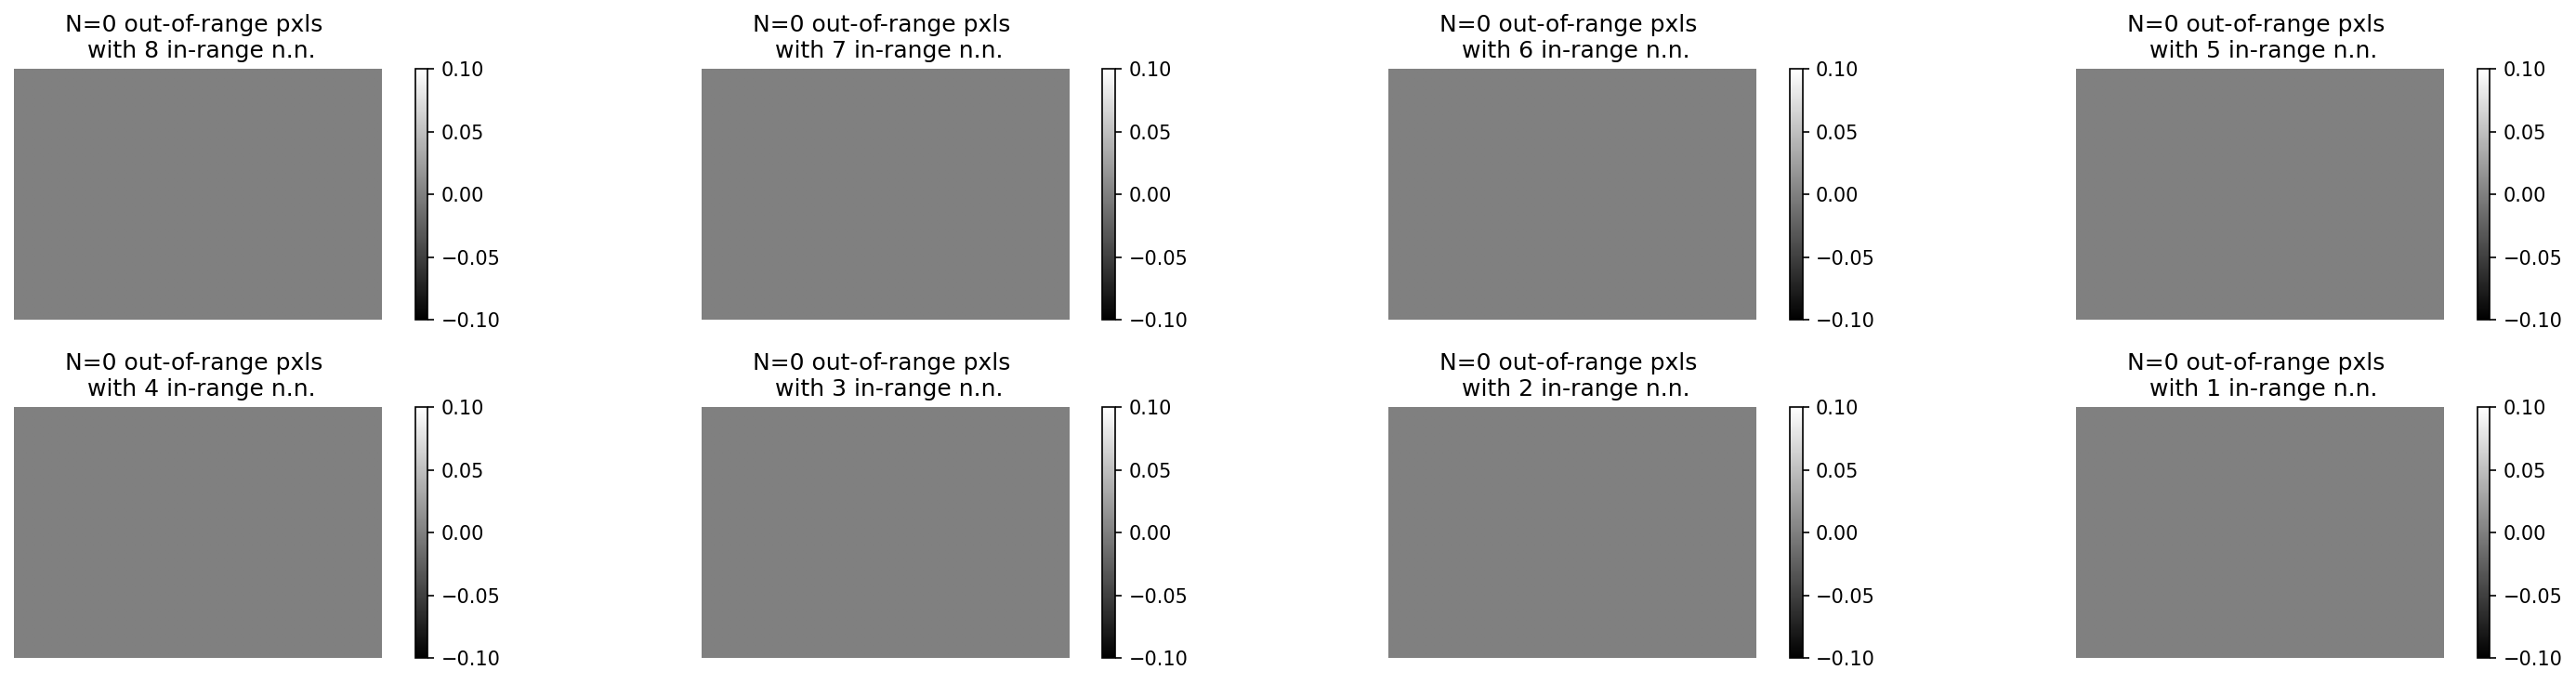

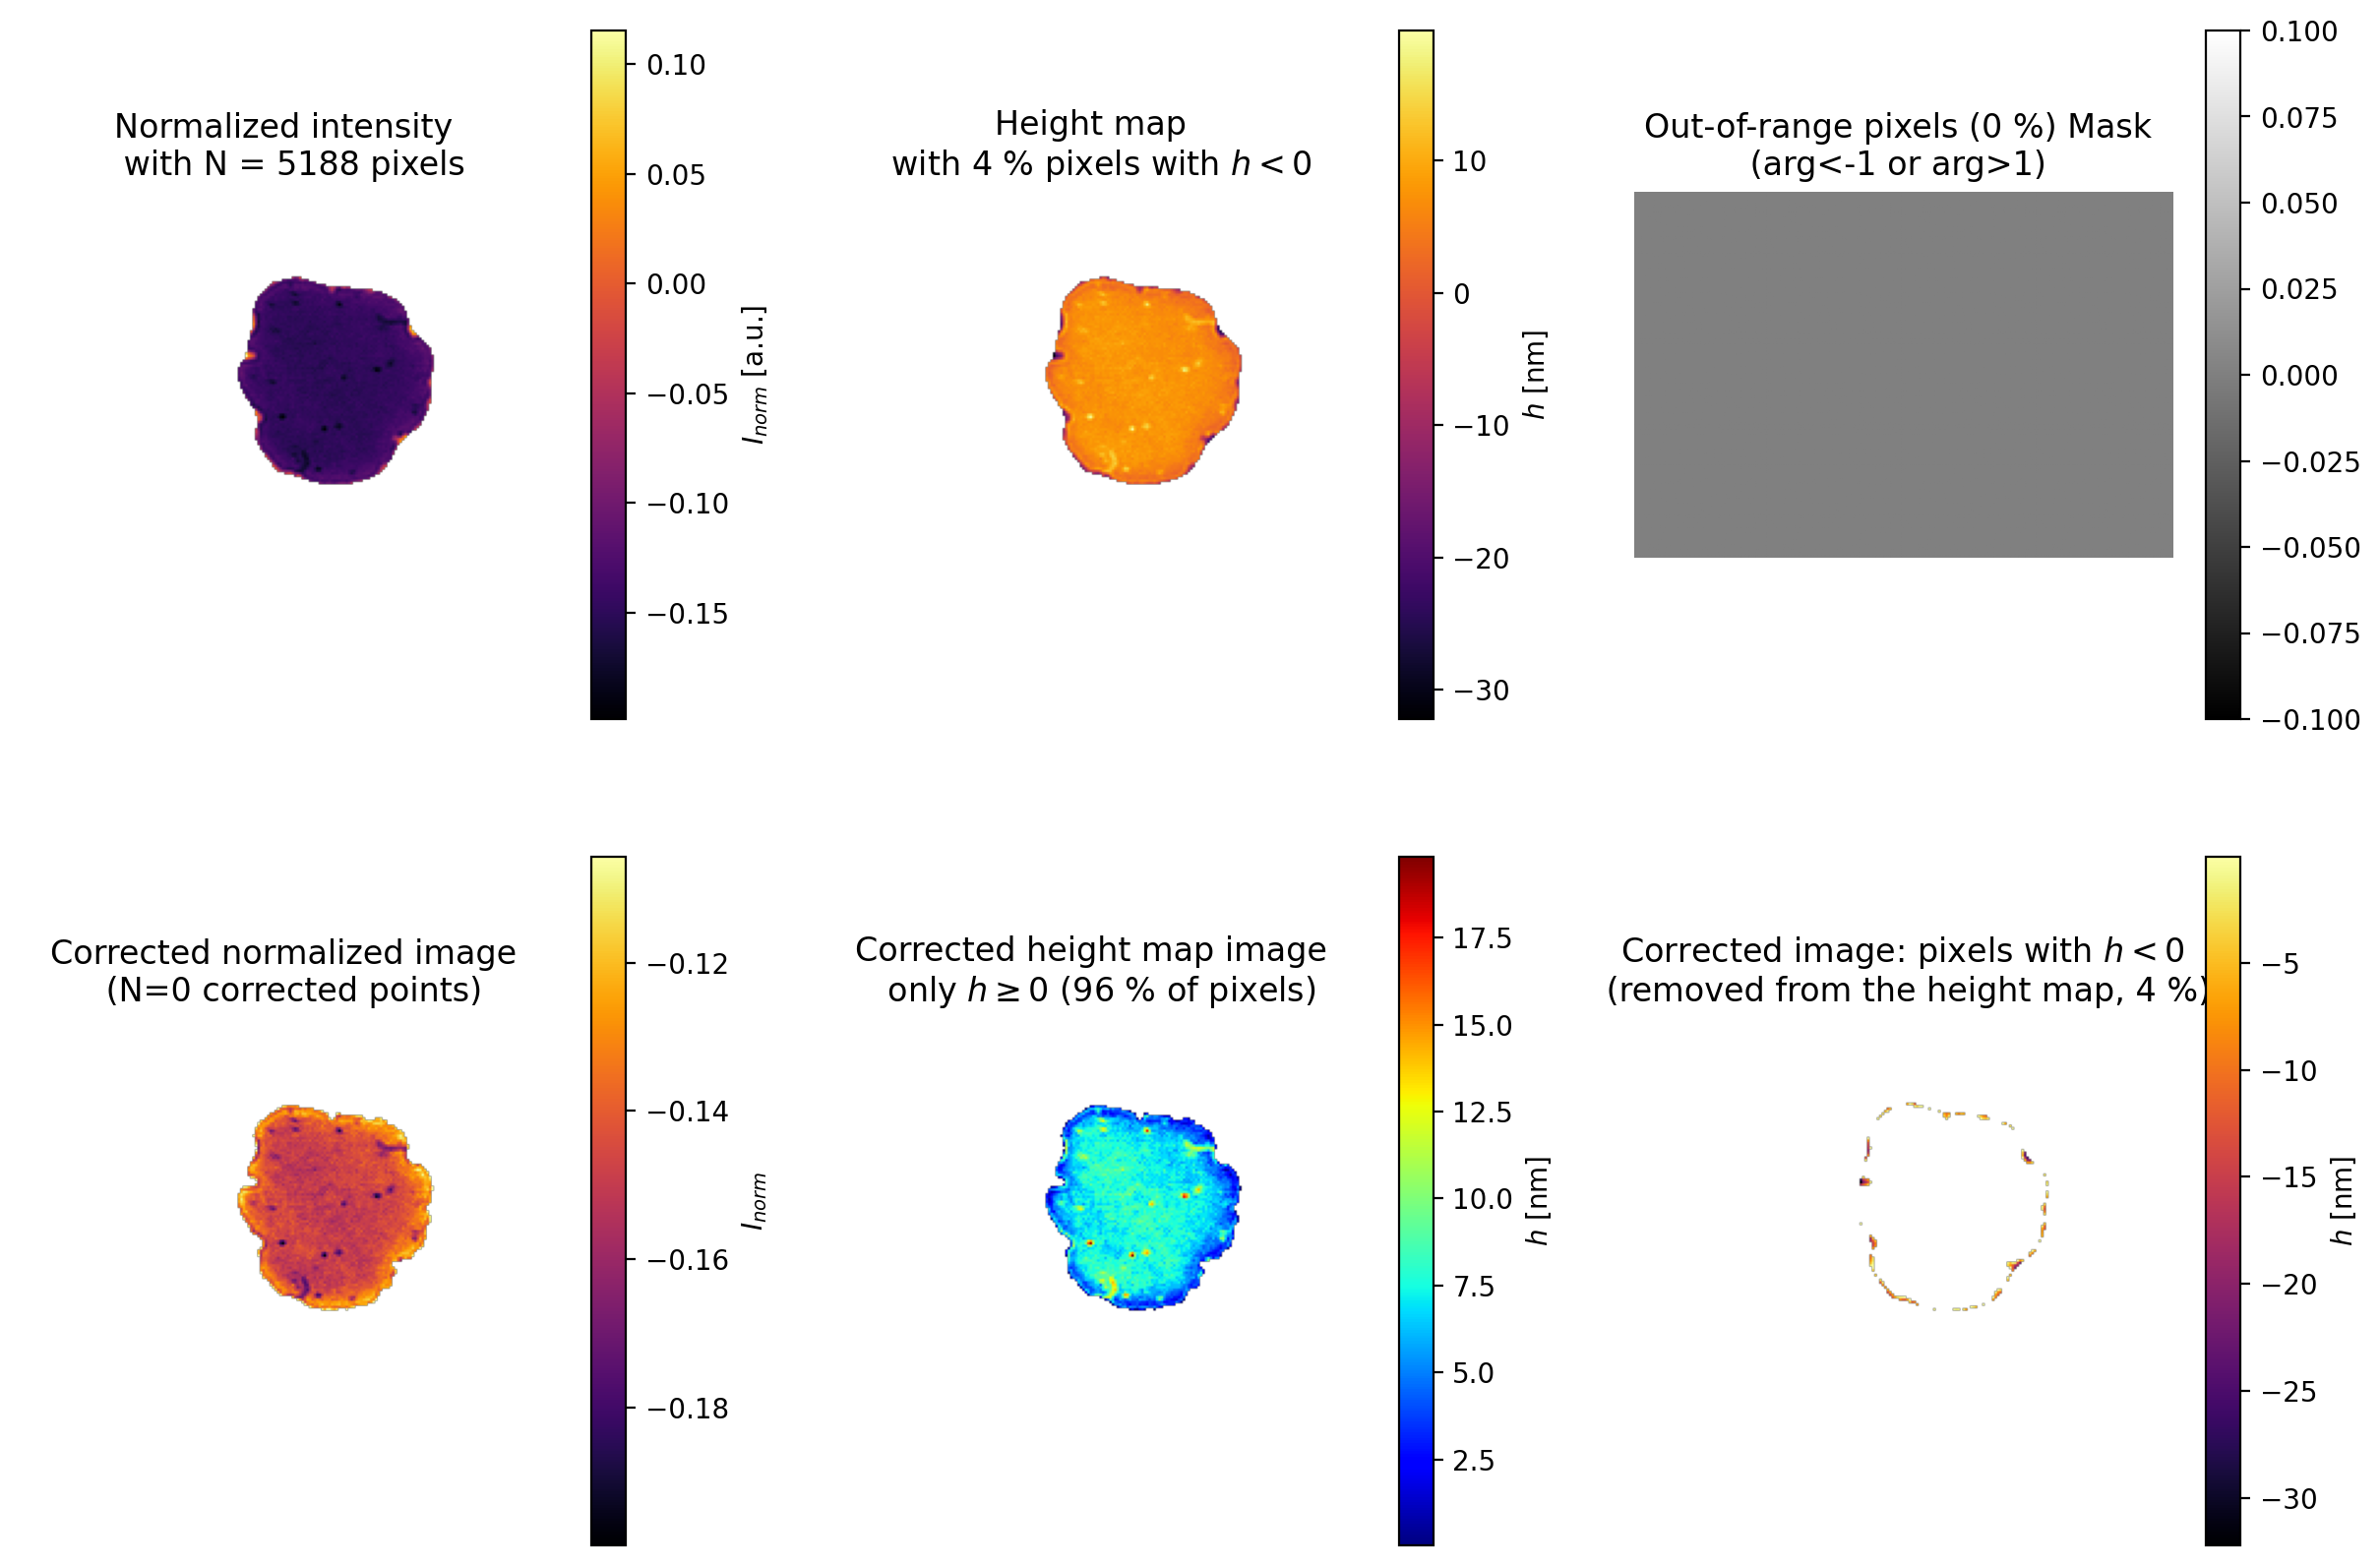

In [20]:
from scipy.ndimage import convolve

# ============================================================================
#   INTENSITY to HEIGHT h(I) CONVERSION and FIX of the OUT-OF-RANGE pixels
# ============================================================================

"""
HYPOTHESIS: - CONTINUITY OF THE MEMBRANE ==> we can correct the out-of-range pixels assuming that they are non-physical values
            - 5 or 3 reflections system
Returns: fixed_normalized_img, height_map_Average_RICMimg
"""

# IF YOU WANT TO TEST: create a 4x4 test image with all pixels = 0.1 except 2 with value = 0.5 (out of range)
#normalized_adhesion_zone_img = np.full((4, 4), 0.1)
#normalized_adhesion_zone_img[1, 1] = 0.5 ; normalized_adhesion_zone_img[1, 2] = 0.5

BRANCH_DATA                = 0            # Select the branch to which data should belong to
CONSIDER_INA_NOT_ZERO      = False        # Do you want to use I(h;INA) or just I(h) ?
SAVE_HEIGHT_PROCESSING_IMG = False        # Do you want to save the adhesion zone identification image? (True or False)


if BRANCH_DATA >= 0:
    if CONSIDER_INA_NOT_ZERO:
        h0_used, Dh_used = h0_numerical, Delta_h_numerical
    else:
        h0_used, Dh_used = h0, Delta_h
    h_min = h0_used + Dh_used * (BRANCH_DATA - 1)        # branch 0 => h_min < 0 (negative heights are kept on purpose)
    h_max = h0_used + Dh_used * BRANCH_DATA
    h_range = np.linspace(h_min, h_max, 500)

    # --- 1) Intensity range of the branch [I_low, I_high] and conversion function (INA = 0 or not)
    if CONSIDER_INA_NOT_ZERO:                            # I(h; INA > 0): numerical lookup table
        lookup = build_lookup(h_min, h_max)
        I_low, I_high = lookup[1][0], lookup[1][-1]      # I_b is sorted increasingly
        to_height = lambda I: height_from_Inorm(I, lookup)
    else:                                                # INA = 0: analytic cosine, |cos| <= 1
        I_low, I_high = Y0_parameter - A_parameter, Y0_parameter + A_parameter
        to_height = lambda I: intensity_to_height_simple(I, Y0_parameter, A_parameter, h0 = h0_used, branch = BRANCH_DATA)

    # --- 2) Create the masks and the height map
    valid_mask_without_nan = Final_Mask
    with np.errstate(invalid="ignore"):
        in_range_mask = (normalized_adhesion_zone_img >= I_low) & (normalized_adhesion_zone_img <= I_high)        # NaN pixels -> False
    out_of_range_mask = valid_mask_without_nan & ~in_range_mask

    height_map = np.full(normalized_adhesion_zone_img.shape, np.nan)
    height_map[in_range_mask] = to_height(normalized_adhesion_zone_img[in_range_mask])   # all in-range pixels, negative heights included
    N_pixels_tot = valid_mask_without_nan.sum()

    with np.errstate(invalid="ignore"):
        negative_height_mask = in_range_mask & (height_map < 0)
    negative_height_image = np.where(negative_height_mask, height_map, np.nan)   # only the pixels with h < 0

    #  --- 3) Allow only NON NEGATIVE heights : h >= 0
    height_map_nonNegative = height_map.copy()
    height_map_nonNegative[negative_height_mask] = np.nan
    Negative_pixels = np.sum(negative_height_mask)
    print(f'There are N = {Negative_pixels}/{N_pixels_tot} ({Negative_pixels/N_pixels_tot*100:.0f} %) pixels with negative height ')

    #  --- 4) FIND HOW MANY pixels are inside the adhesion zone for which arg > 1 or arg < -1
    out_of_range_image = np.where(out_of_range_mask, normalized_adhesion_zone_img, np.nan)             # I_norm of the pixels outside the cosine range

    print(f"Allowed I_norm range: [{I_low:.4f}, {I_high:.4f}]   (h from {h_min:.1f} to {h_max:.1f} nm)")
    print(f"In range: {in_range_mask.sum()} / {N_pixels_tot} pixels ({100 * in_range_mask.sum() / N_pixels_tot:.1f} %),  "
          f"of which h < 0: {negative_height_mask.sum()},  out of range: {out_of_range_mask.sum()}")

    #  --- 5) FIX the pixels inside the adhesion zone that are out of range (arg > 1 or arg < -1)
    #  Each out-of-range pixel gets the mean of its in-range nearest neighbours (n.n., 8-neighbourhood).
    #  Pixels with the MOST in-range n.n. are fixed first; fixed pixels then count as in-range for the next steps.
    kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=float)

    frame = normalized_adhesion_zone_img.copy()          # we avoid OVERWRITING the original image
    frame[out_of_range_mask] = np.nan

    # diagnostic: out-of-range pixels grouped by their number of in-range n.n. at the beginning
    n_nn_start = convolve((~np.isnan(frame)).astype(float), kernel, mode='constant', cval=0)
    fig = plt.figure(figsize=(20, 5), dpi=150)
    for n in range(8, 0, -1):
        mask_n = out_of_range_mask & (n_nn_start == n)
        plt.subplot(2, 4, 9 - n)
        display_image(mask_n.astype(float), axis='off',
                      img_title=f'N={np.sum(mask_n)} out-of-range pxls \n with {n} in-range n.n.',
                      cmap_img='gray', color_bar_label='')
    plt.tight_layout()

    while True:
        still_nan = np.isnan(frame) & out_of_range_mask
        if not still_nan.any():
            break                                        # everything is fixed
        in_range = ~np.isnan(frame)
        neighbor_count = convolve(in_range.astype(float), kernel, mode='constant', cval=0)
        neighbor_sum   = convolve(np.where(in_range, frame, 0.0), kernel, mode='constant', cval=0)

        candidates = still_nan & (neighbor_count > 0)
        if not candidates.any():
            break                                        # the remaining pixels have no valid neighbour at all: they cannot be fixed
        fixable = candidates & (neighbor_count == neighbor_count[candidates].max())   # pixels with the highest number of valid n.n.
        frame[fixable] = neighbor_sum[fixable] / neighbor_count[fixable]              # all fixed together, using the same old values

    fixed_normalized_img = frame
    N_fixed = np.sum(out_of_range_mask & ~np.isnan(fixed_normalized_img))
    print(f"Out-of-range pixels: {out_of_range_mask.sum()},  fixed: {N_fixed},  not fixable (no valid neighbour): {out_of_range_mask.sum() - N_fixed}")

    # --- 6) Recalculate the height on the fixed image (all its pixels are now inside the cosine range)
    img_h_for_plot = height_map                          # for the plot, before the fix (negative heights included)
    valid_fixed = ~np.isnan(fixed_normalized_img)
    height_fixed_all = np.full(fixed_normalized_img.shape, np.nan)
    height_fixed_all[valid_fixed] = to_height(fixed_normalized_img[valid_fixed])    # negative heights included

    with np.errstate(invalid="ignore"):
        negative_fixed_mask = height_fixed_all < 0
    height_map_Average_RICMimg = np.where(negative_fixed_mask, np.nan, height_fixed_all)                 # only non-negative heights
    fixed_normalized_img = np.where(negative_fixed_mask, np.nan, fixed_normalized_img)   # the removed ones (h < 0)
    negative_height_image_fixed = np.where(negative_fixed_mask, height_fixed_all, np.nan)   # the removed ones (h < 0)
    N_nonneg = np.sum(np.isfinite(height_map_Average_RICMimg)) ; N_neg_fixed = np.sum(negative_fixed_mask)

    # PLOT
    imgs_to_plot = [normalized_adhesion_zone_img, img_h_for_plot, out_of_range_mask, fixed_normalized_img, height_map_Average_RICMimg, negative_height_image_fixed]
    name_height_map = f'Height map \n with {Negative_pixels/N_pixels_tot*100:.0f} % pixels with $h<0$'
    if CONSIDER_INA_NOT_ZERO: name_height_map += f'\n (INA = {ILLUMINATION_NUMERICAL_APERTURE})'
    imgs_to_plot_title = [  f'Normalized intensity \n with N = {N_pixels_tot} pixels', name_height_map,
                            f'Out-of-range pixels ({out_of_range_mask.sum()/N_pixels_tot*100:.0f} %) Mask \n (arg<-1 or arg>1)  ',
                            f'Corrected normalized image \n (N={N_fixed} corrected points)',
                            f'Corrected height map image \n only $h \\geq 0$ ({N_nonneg/N_pixels_tot*100:.0f} % of pixels)',
                            f'Corrected image: pixels with $h<0$ \n (removed from the height map, {N_neg_fixed/N_pixels_tot*100:.0f} %)']
    color_bars = ['inferno', 'inferno', 'gray', 'inferno', 'jet', 'inferno']
    color_bar_labels = [r'$I_{norm}$ [a.u.]', r'$h$ [nm]', '', r'$I_{norm}$', r'$h$ [nm]', r'$h$ [nm]']

    fig = plt.figure(figsize=(15, 10), dpi=200) # Plot
    for j, _ in enumerate(imgs_to_plot):
        plt.subplot(2, 3, j + 1)
        display_image(imgs_to_plot[j], axis='off', img_title=imgs_to_plot_title[j], cmap_img=color_bars[j], color_bar_label=color_bar_labels[j])
    if SAVE_HEIGHT_PROCESSING_IMG: plt.savefig(save_results_directory + r'\ ' + file_name + '_5_Height_map.png', dpi=300, bbox_inches='tight')

<>:136: SyntaxWarning: invalid escape sequence '\m'
<>:141: SyntaxWarning: invalid escape sequence '\m'
<>:136: SyntaxWarning: invalid escape sequence '\m'
<>:141: SyntaxWarning: invalid escape sequence '\m'
C:\Users\nicol\AppData\Local\Temp\ipykernel_3000\703255192.py:136: SyntaxWarning: invalid escape sequence '\m'
  ax7.set_title(f'Radial profile \n major axis Width = {width_major_axis} pxl, Length L = {major_axis_len * 2 * PIXEL_SIZE/1000:.3g} $\mu$m')
C:\Users\nicol\AppData\Local\Temp\ipykernel_3000\703255192.py:141: SyntaxWarning: invalid escape sequence '\m'
  ax7.set(xlabel='Radial distance [$\mu$m]', ylabel=r'Intensity $I_{norm}$')



Ellipse fit: center = (127.74, 76.21), axes length = (75.47, 83.66), angle = 169.16°

Gaussian fit:  <h> = 7.27,  σ = 1.03,  y₀ = 12.63,  A = 347.97


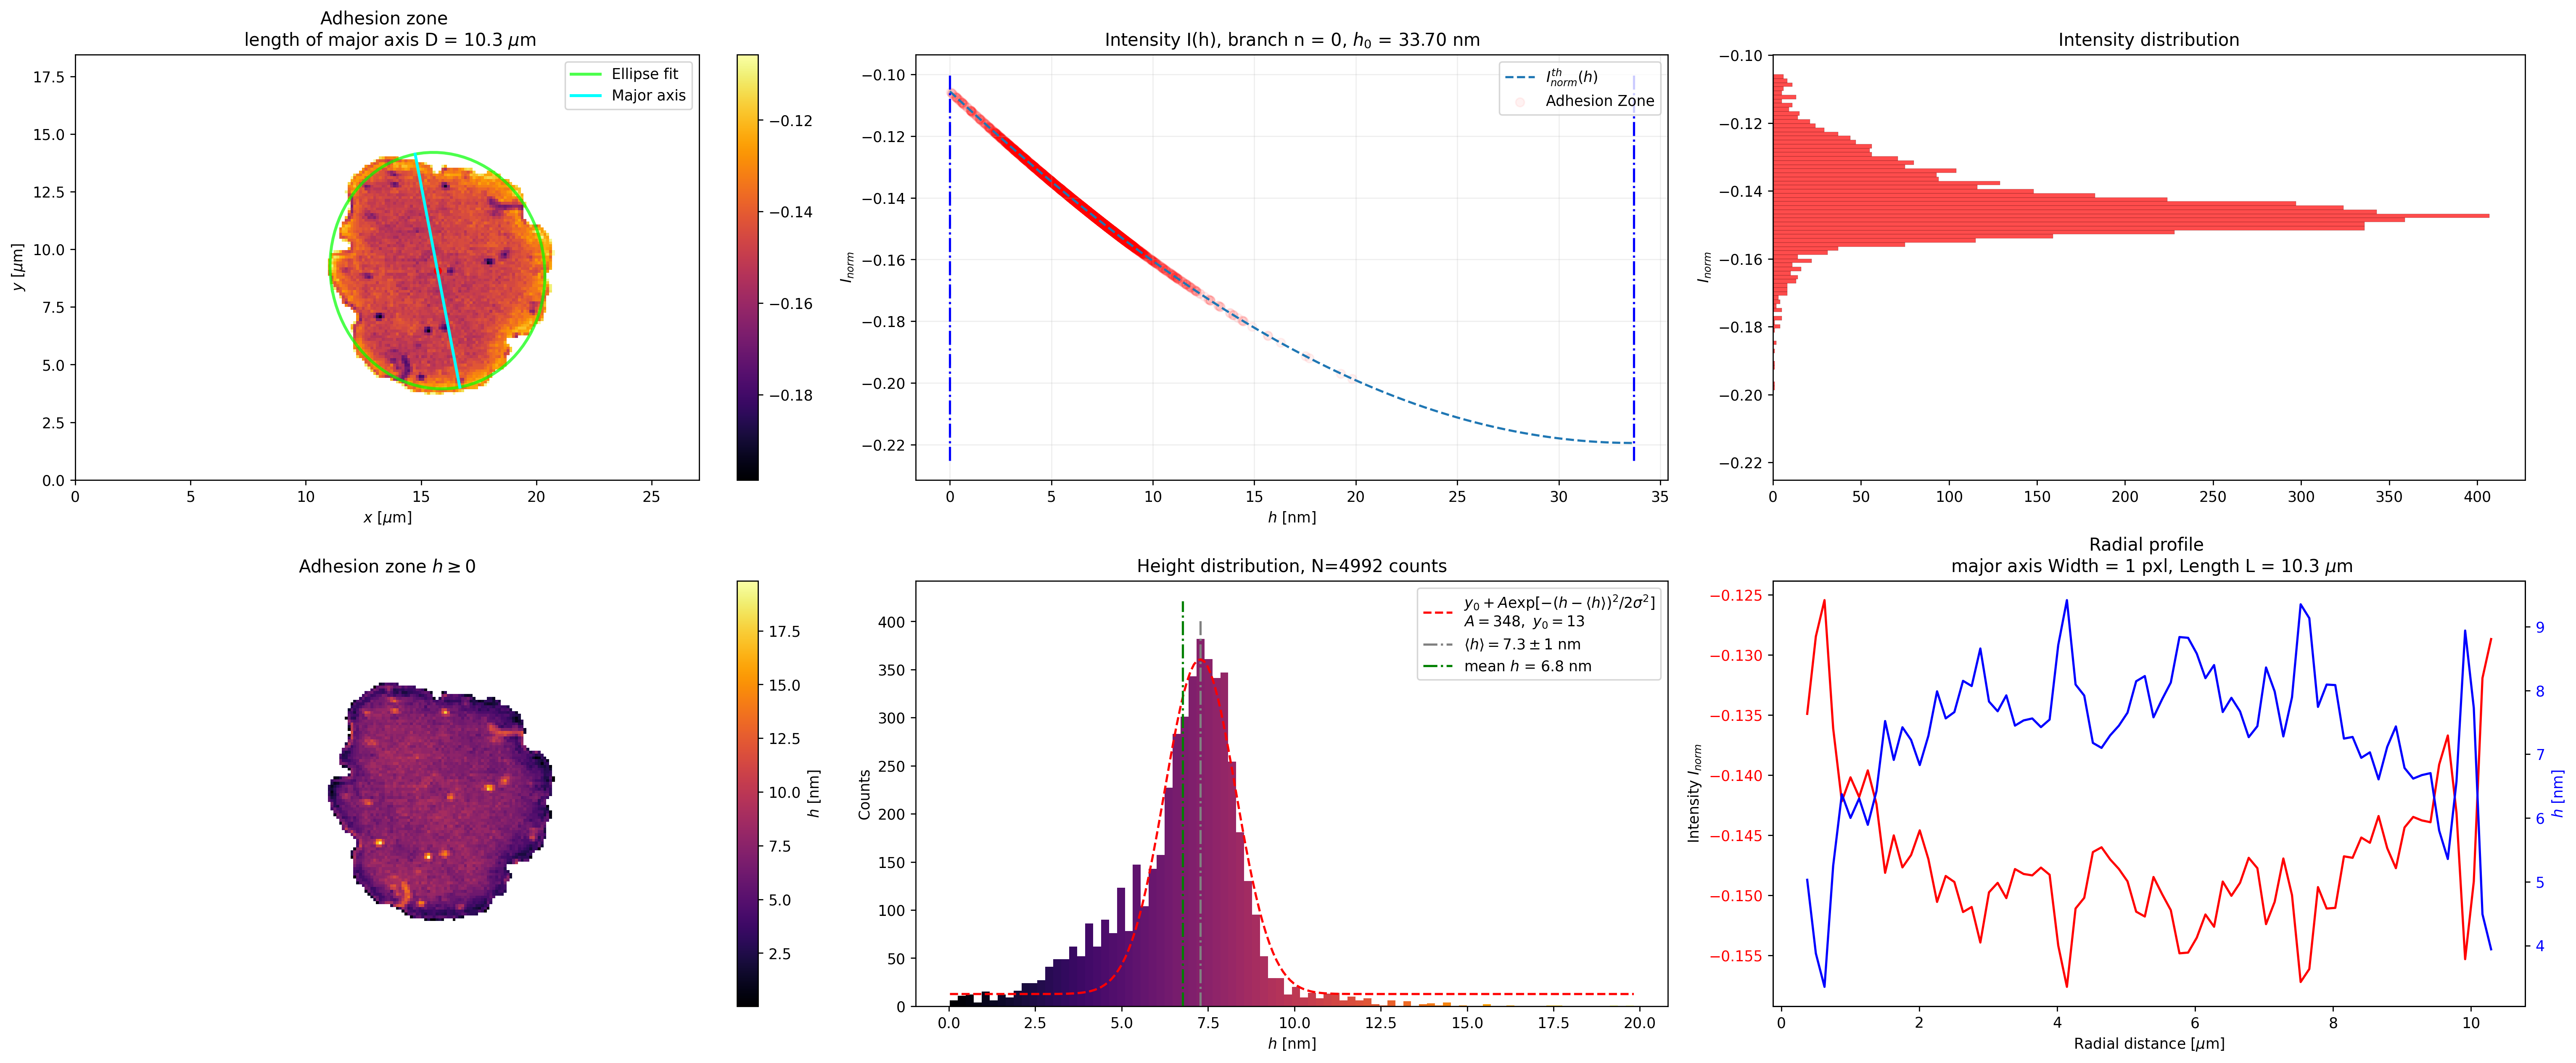

In [21]:
import scipy.ndimage as ndimage
from scipy.ndimage import gaussian_filter
from scipy import optimize
import cv2
import numpy as np
import matplotlib.pyplot as plt

def height_analysis(  fixed_normalized_img, height_image, branch_data, h_range, bin_histo, width_major_axis):
    """
    Full analysis of a RICM adhesion zone:
      - Ellipse fit + major axis profile
      - I(h) mapping
      - Height & intensity distributions
    """

    # ── Ellipse fit on contour ────────────────────────────────────────────────
    binary_mask             = np.isfinite(fixed_normalized_img).astype(np.uint8) * 255
    contours, _             = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    has_ellipse             = False
    if contours:
        main_contour = max(contours, key=cv2.contourArea)
        if len(main_contour) >= 5:
            has_ellipse                  = True
            (xc, yc), (d1, d2), angle   = cv2.fitEllipse(main_contour)
            phi                          = np.deg2rad(angle)
            a, b                         = d1 / 2, d2 / 2
            theta                        = np.linspace(0, 2 * np.pi, 100)
            ex = xc + a*np.cos(theta)*np.cos(phi) - b*np.sin(theta)*np.sin(phi)
            ey = yc + a*np.cos(theta)*np.sin(phi) + b*np.sin(theta)*np.cos(phi)

            major_axis_len  = max(d1, d2) / 2    
            print(f'\nEllipse fit: center = ({xc:.2f}, {yc:.2f}), axes length = ({d1:.2f}, {d2:.2f}), angle = {angle:.2f}°')
            x1 = xc - major_axis_len * np.sin(phi);  y1 = yc + major_axis_len * np.cos(phi)
            x2 = xc + major_axis_len * np.sin(phi);  y2 = yc - major_axis_len * np.cos(phi)
            num_points      = int(max(d1, d2))
            line_x          = np.linspace(x1, x2, num_points)
            line_y          = np.linspace(y1, y2, num_points)
            r_axis          = np.linspace(0, major_axis_len * 2, num_points)

    # ── Gaussian fit on height distribution ───────────────────────────────────
    gauss           = Fit_Gaussian(height_image.ravel(), normalized=False)
    x0, sigma, y0_g, A_g = gauss.hist_fitting(bins=bin_histo, show=False)
    x_fit           = np.linspace(np.nanmin(height_image), np.nanmax(height_image), 200)
    gauss_curve     = y0_g + A_g * np.exp(-(x_fit - x0)**2 / (2 * sigma**2))

    print(f'\nGaussian fit:  <h> = {x0:.2f},  σ = {sigma:.2f},  y₀ = {y0_g:.2f},  A = {A_g:.2f}')

    # ── Figure layout ─────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(25, 10), dpi=250, layout='constrained')
    y_min, y_max = None, None   # set after first scatter plot

    # ── 1: Adhesion zone image + ellipse ─────────────────────────────────────
    ax1 = fig.add_subplot(231)
    ax1.set_title(f'Adhesion zone \n length of major axis D = {major_axis_len*PIXEL_SIZE/1000*2:.3g} $\\mu$m')
    size_x, size_y = fixed_normalized_img.shape  
    extent = [0, size_y * PIXEL_SIZE / 1000, 0, size_x * PIXEL_SIZE / 1000]     # Calculate physical extent: [xmin, xmax, ymin, ymax]

    # Plot the image with the specified extent and store the reference
    im = ax1.imshow(np.flipud(fixed_normalized_img), cmap='inferno', origin='lower', aspect='equal', extent=extent)
    ax1.set(xlabel='$x$ [$\\mu$m]', ylabel='$y$ [$\\mu$m]')
    fig.colorbar(im, ax=ax1)
    
    if has_ellipse:
        pixel_size_um = PIXEL_SIZE / 1000
        
        # Invert y-coordinates because of np.flipud(), then scale to microns
        ey_flipped = (size_x - ey) * pixel_size_um
        y1_flipped = (size_x - y1) * pixel_size_um
        y2_flipped = (size_x - y2) * pixel_size_um
        yc_flipped = (size_x - yc) * pixel_size_um
        
        # x-coordinates only need scaling
        ex_scaled = ex * pixel_size_um
        x1_scaled = x1 * pixel_size_um
        x2_scaled = x2 * pixel_size_um
        xc_scaled = xc * pixel_size_um

        ax1.plot(ex_scaled, ey_flipped, color='lime', linewidth=2, alpha=0.7, label='Ellipse fit')
        ax1.plot([x1_scaled, x2_scaled], [y1_flipped, y2_flipped], color='cyan', linewidth=2, label='Major axis')
        ax1.scatter(xc_scaled, yc_flipped, color='red', s=20)
        ax1.legend(loc='best')

    # ── 2: I(h) scatter + theoretical curve ──────────────────────────────────
    ax2 = fig.add_subplot(232)
    if CONSIDER_INA_NOT_ZERO: Thoeretical_intensity = I_norm_numeric(h_range, lam=LAMBDA_LIGHT, n0=n_0, n_w= 1.333, n_outer=n_1, n_membrane=n_2, n_inner=n_3, d_h2o = WATER_LAYER_THICKNESS,
                            d=MEMBRANE_THICKNESS, INA=ILLUMINATION_NUMERICAL_APERTURE, how_many_reflections = HOW_MANY_REFLECTIONS, angular=True, N = 1000)
    else: Thoeretical_intensity = Y0_parameter - A_parameter * np.cos(4 * np.pi * n_1 / LAMBDA_LIGHT * (h_range - h0_used))
    
    ax2.plot(h_range, Thoeretical_intensity , '--', label='$I^{th}_{norm}(h)$')
    ax2.scatter(height_image, fixed_normalized_img, color='r', alpha=0.05, label='Adhesion Zone')
    y_min, y_max = ax2.get_ylim()
    ax2.vlines([0, h0_used], y_min, y_max, colors='blue', linestyles='-.', alpha=1)
    ax2.set(xlabel='$h$ [nm]', ylabel='$I_{norm}$',
            title=f'Intensity I(h), branch n = {branch_data}, $h_0$ = {h0_used:.2f} nm')
    ax2.legend(loc='best'); ax2.grid(alpha=0.2)

    # ── 3: Intensity histogram (horizontal) ───────────────────────────────────
    ax3 = fig.add_subplot(233)
    ax3.hist(fixed_normalized_img.ravel(), color='red', alpha=0.7, bins='auto', orientation='horizontal', edgecolor='black', linewidth=0.1)
    ax3.set(ylabel='$I_{norm}$', title='Intensity distribution')
    if y_min is not None:
        ax3.set_ylim(y_min, y_max)

    # ── 4: Height map ─────────────────────────────────────────────────────────
    fig.add_subplot(234)
    display_image(height_image, img_title='Adhesion zone $h \\geq 0$',
                  cmap_img='inferno', color_bar_label='$h$ [nm]', axis='off')

    # ── 6: Height histogram + Gaussian fit ───────────────────────────────────
    ax6  = fig.add_subplot(235)
    cmap = plt.cm.inferno.copy(); cmap.set_bad(color='white', alpha=0)
    n_counts, bins_out, patches = ax6.hist(height_image.ravel(), bins=bin_histo,
                                           density=False, color='green')
    bin_centers  = 0.5 * (bins_out[:-1] + bins_out[1:])
    norm_centers = (bin_centers - bin_centers.min()) / (bin_centers.max() - bin_centers.min())
    for c, p in zip(norm_centers, patches):
        plt.setp(p, 'facecolor', cmap(c))
    ax6.plot(x_fit, gauss_curve, 'r--',
             label=f'$y_0 + A\\exp[-(h-\\langle h\\rangle)^2/2\\sigma^2]$\n$A={A_g:.0f},\\ y_0={y0_g:.2g}$')
    ax6.vlines(x0, *ax6.get_ylim(), colors='gray', linestyles='-.', label=f'$\\langle h\\rangle = {x0:.2g} \\pm {sigma:.1g}$ nm')
    ax6.vlines(np.nanmean(height_image), *ax6.get_ylim(), colors='green', linestyles='-.', label=f'mean $h$ = {np.nanmean(height_image):.2g} nm')
    ax6.set(xlabel='$h$ [nm]', ylabel='Counts', title=f'Height distribution, N={int(n_counts.sum())} counts')
    ax6.legend(loc='best')

    # ── 7: Radial intensity + height along major axis ─────────────────────────
    if has_ellipse:
        ax7  = fig.add_subplot(236)
        offsets = range(-round(width_major_axis/2), round(width_major_axis/2) + 1)
        height_profiles = [ndimage.map_coordinates(height_image, [line_y + i, line_x], order=1) for i in offsets]
        intensity_profiles = [ndimage.map_coordinates(fixed_normalized_img, [line_y + i, line_x], order=1) for i in offsets]
        
        radial   = np.mean(height_profiles, axis=0)  # mean over the offset ==> considering the width of the line
        radial_intensity = np.mean(intensity_profiles, axis=0) 
        mask_fin = np.isfinite(radial)

        ax7.set_title(f'Radial profile \n major axis Width = {width_major_axis} pxl, Length L = {major_axis_len * 2 * PIXEL_SIZE/1000:.3g} $\mu$m')
        ax7_r = ax7.twinx()
        r_axis = np.linspace(0, major_axis_len * 2 * PIXEL_SIZE / 1000, len(radial))  # in microns
        ax7.plot(r_axis[mask_fin],  radial_intensity[mask_fin], color='red',  label='$I_r$')
        ax7_r.plot(r_axis[mask_fin], radial[mask_fin], color='blue', linestyle='-', label='$h$')
        ax7.set(xlabel='Radial distance [$\mu$m]', ylabel=r'Intensity $I_{norm}$')
        ax7.tick_params(axis='y', labelcolor='red')
        ax7_r.set_ylabel('$h$ [nm]', color='blue')
        ax7_r.tick_params(axis='y', labelcolor='blue')
    if SAVE_HEIGHT_IMG : plt.savefig( save_results_directory + r'\ ' + file_name +  r'_6_Height_analysis.png' , dpi = 300, bbox_inches='tight')  


# ── Run ───────────────────────────────────────────────────────────────────────
WIDTH_MAJOR_AXIS = 1
BIN_HISTO        = 'auto'
SAVE_HEIGHT_IMG  = True
PIXEL_SIZE       =  123        # 1 pixel equals to ... nm

if BRANCH_DATA == 0 : h_range = np.linspace( 0 , h_max , 500)
height_analysis(fixed_normalized_img, height_map_Average_RICMimg, BRANCH_DATA, h_range,
                BIN_HISTO, WIDTH_MAJOR_AXIS)

<>:45: SyntaxWarning: invalid escape sequence '\p'
<>:51: SyntaxWarning: invalid escape sequence '\p'
<>:83: SyntaxWarning: invalid escape sequence '\g'
<>:45: SyntaxWarning: invalid escape sequence '\p'
<>:51: SyntaxWarning: invalid escape sequence '\p'
<>:83: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nicol\AppData\Local\Temp\ipykernel_3000\2986425904.py:45: SyntaxWarning: invalid escape sequence '\p'
  title_height_map = r'Mean height map $\langle h_{ij} \rangle$'+f' \n Average height'+r' $\langle h \rangle$' + f' = {average_height_value:.2g} $\pm$ {std_height_value:.2g} nm '
C:\Users\nicol\AppData\Local\Temp\ipykernel_3000\2986425904.py:51: SyntaxWarning: invalid escape sequence '\p'
  title_height_map = r'Difference $\langle h_{ij} \rangle - h_{ij}|_{\langle I \rangle}  $' + f'\n Average difference = {average_difference:.2g} $\pm \sigma$ = {np.nanstd(height_map_RICMimgs - height_map_Average_RICMimg):.2g} nm'
C:\Users\nicol\AppData\Local\Temp\ipykernel_3000\2986425904.py:

Exponential fit parameters: A = 12, t0 = 2.9 frames


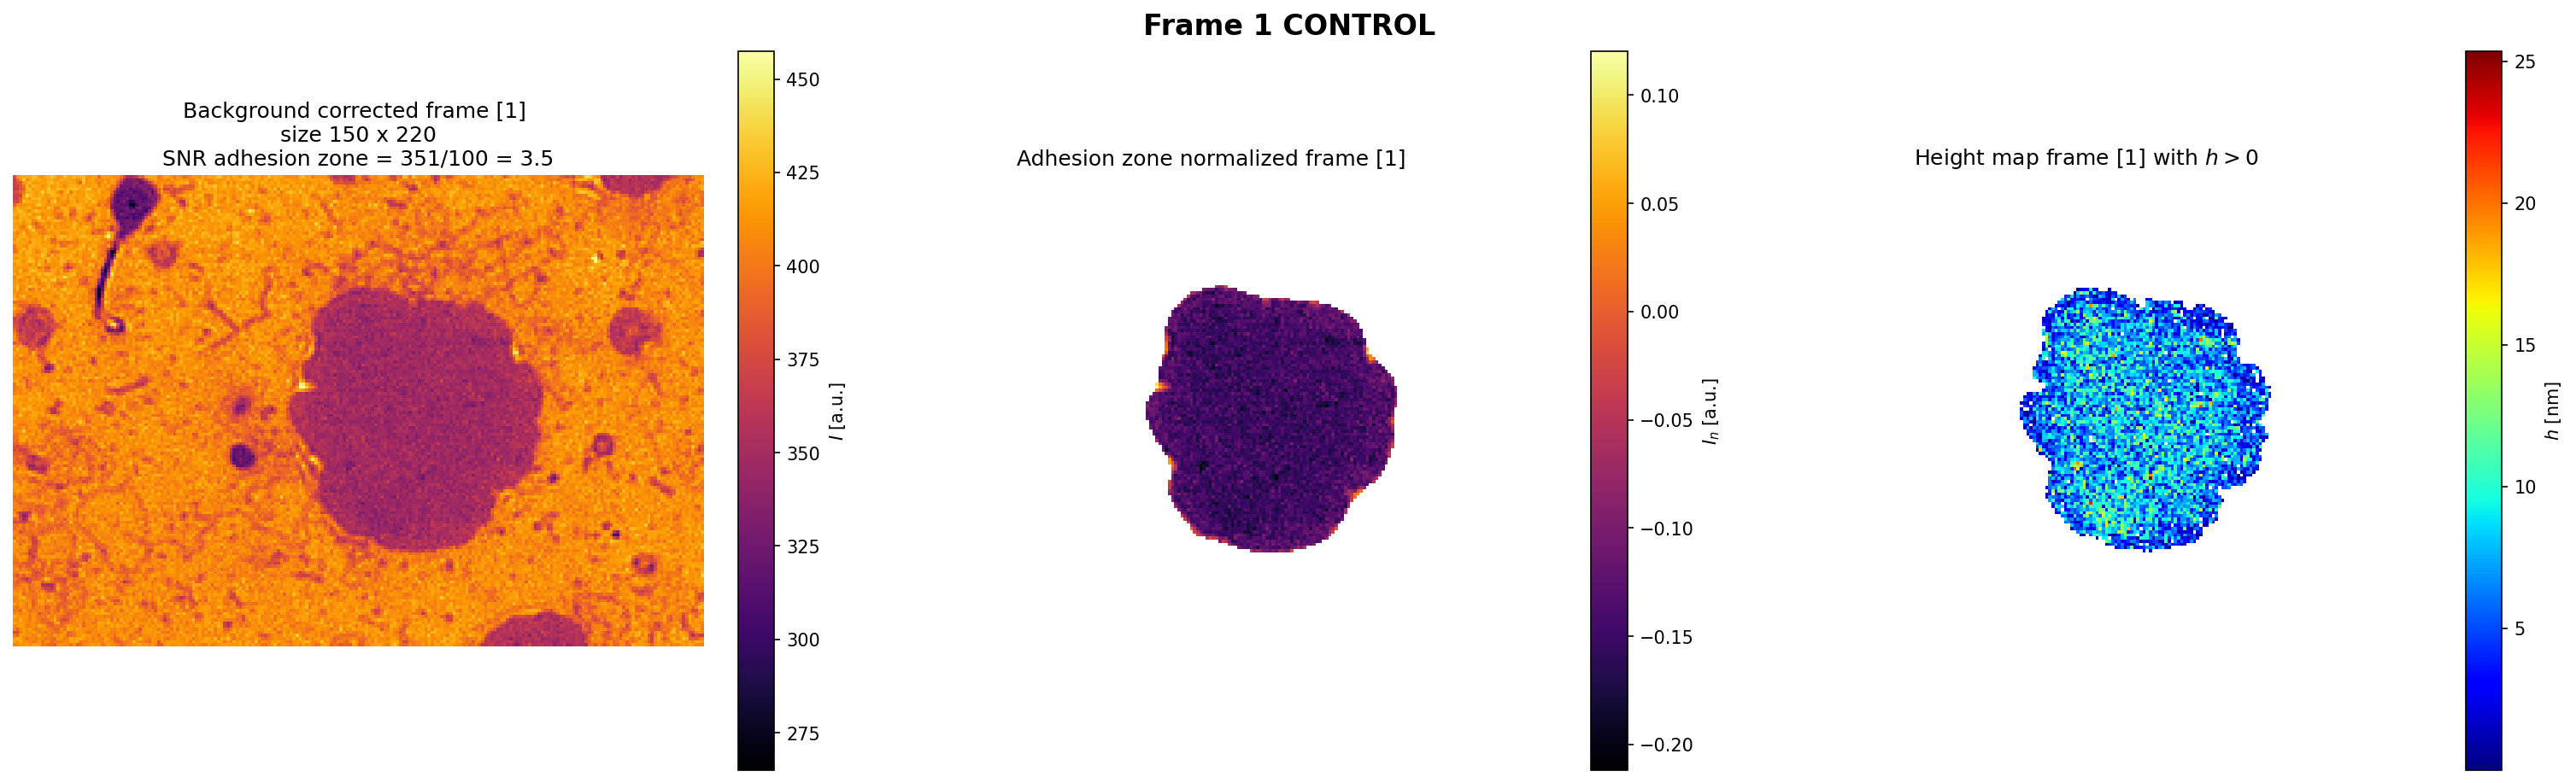

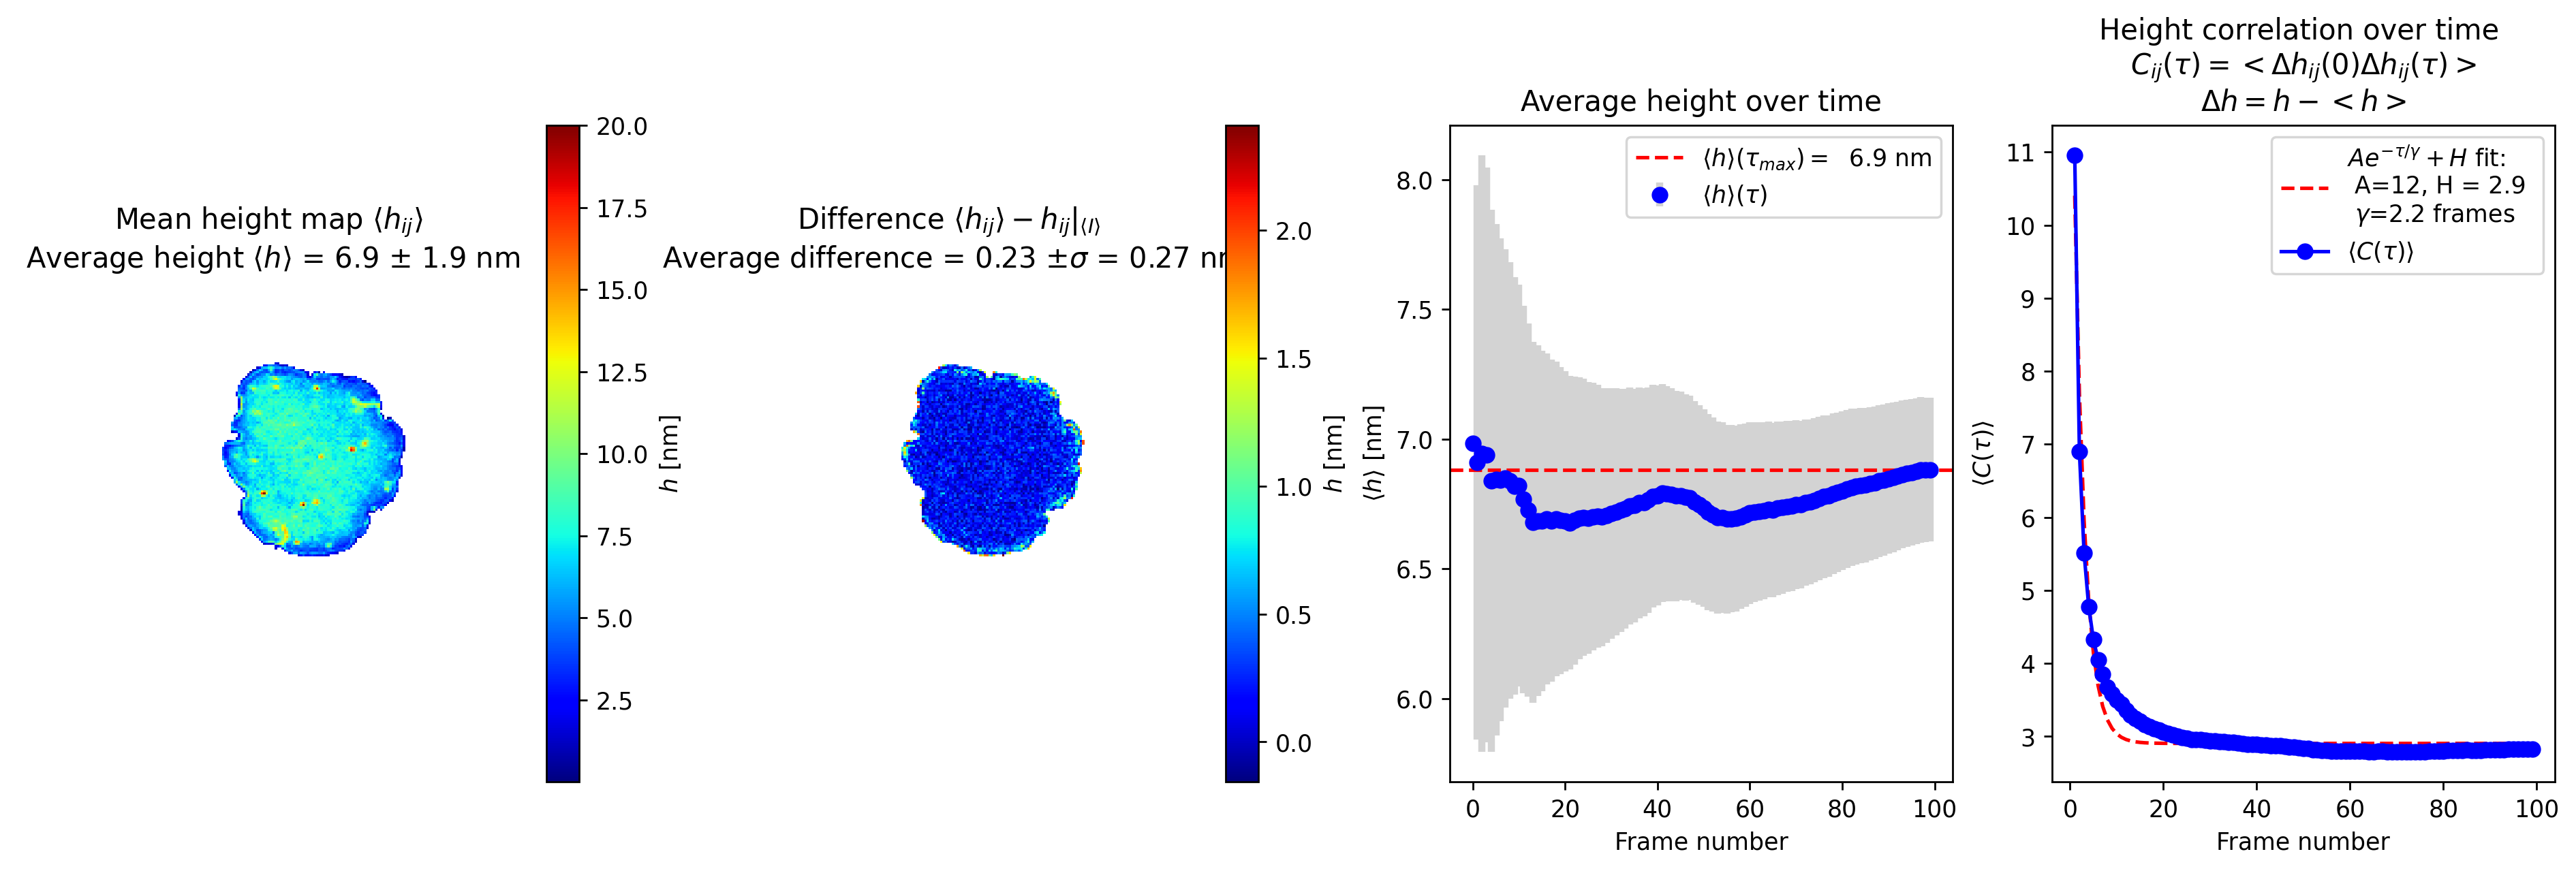

In [47]:
# ============================================================================
#           ANALYSIS OF HEIGHT CORRELATION
# ============================================================================

"""Evaluation of the height map for each frame h_ijk and the correlation of the height map with the average height map <h_ij>"""

INDEX_FRAME_TO_PLOT = 1   # select a frame from the RICM movie for the control. Put 'None' if you don't want to plot any frame


adhesion_zone_normalized_imgs, bkg_corrected_adhesion_zones, bkg_corrected_ricm_imgs, height_maps = [] , [], [], []
for i, frame in enumerate(RICM_imgs_I_raws): 

    cropped_frame = frame[ Y_START_CROP :Y_END_CROP , X_START_CROP:X_END_CROP]  # crop the image to the same size as the mask
    darkCurrents_bkg_corrected_frame = cropped_frame - Dark_currents_avg_bkg  # subtract the dark currents from the current frame
    bkg_corrected_frame = (darkCurrents_bkg_corrected_frame - reconstructed_bkg) + np.average(reconstructed_bkg) # correct the image by subtracting the background obtained from the average ricm image by fitting with 2nd order polynomial 
    normalized_frame = (bkg_corrected_frame - avg_corrected_background)/avg_corrected_background  # Normalize the image by using the average corrected bkg I_1, obtained previously
    adhesion_zone_normalized_frame = normalized_frame.copy(); adhesion_zone_I_raw_frame = darkCurrents_bkg_corrected_frame.copy()  # extract the adhesion zone by imposing the mask obtained from the average ricm image 
    adhesion_zone_normalized_frame[~Final_Mask] = np.nan ; adhesion_zone_I_raw_frame[~Final_Mask] = np.nan

    # height frame. Discard negative heights. Not correct out-of-range pixels but discard them
    in_range_mask_frame = (adhesion_zone_normalized_frame >= I_low) & (adhesion_zone_normalized_frame <= I_high)        # NaN pixels -> False
    height_map_frame = np.full(adhesion_zone_normalized_frame.shape, np.nan)
    height_map_frame[in_range_mask_frame] = to_height(adhesion_zone_normalized_frame[in_range_mask_frame])   # all in-range pixels, negative heights included
    height_map_frame[height_map_frame < 0] = np.nan 

    adhesion_zone_normalized_imgs.append(adhesion_zone_normalized_frame) ; bkg_corrected_adhesion_zones.append(adhesion_zone_I_raw_frame) ; bkg_corrected_ricm_imgs.append(bkg_corrected_frame); height_maps.append(height_map_frame)
    if INDEX_FRAME_TO_PLOT is not None and i == INDEX_FRAME_TO_PLOT:
        fig_index_plot = plt.figure(figsize=(20, 6), dpi=150, layout='constrained')
        fig_index_plot.suptitle(f'Frame {INDEX_FRAME_TO_PLOT} CONTROL', fontsize=16, fontweight='bold')
        ax1 = fig_index_plot.add_subplot(131)
        display_image(bkg_corrected_frame, axis='off', img_title= f'Background corrected frame [{INDEX_FRAME_TO_PLOT}] \n size {cropped_image.shape[0]} x {cropped_image.shape[1]} \n SNR adhesion zone = {np.nanmean(bkg_corrected_frame[Final_Mask]):.3g}/{Dark_currents_avg_bkg:.3g} = {np.nanmean(bkg_corrected_frame[Final_Mask])/Dark_currents_avg_bkg:.2g} ', cmap_img='inferno', color_bar_label='$I$ [a.u.]')
        ax2 = fig_index_plot.add_subplot(132)
        display_image(adhesion_zone_normalized_frame, axis='off', img_title= f'Adhesion zone normalized frame [{INDEX_FRAME_TO_PLOT}]', cmap_img='inferno', color_bar_label='$I_n$ [a.u.]')
        ax3 = fig_index_plot.add_subplot(133)
        display_image(height_map_frame, axis='off', img_title= f'Height map frame [{INDEX_FRAME_TO_PLOT}] with $h>0$', cmap_img='jet', color_bar_label='$h$ [nm]')
        fig_index_plot.clear


fig = plt.figure(figsize=(15, 5), dpi=250, layout='constrained')

# --- 1) Height map
ax1 = fig.add_subplot(141)
height_map_RICMimgs = np.nanmean(height_maps, axis=0)  # ---  Average height map: average over the RICM movie frames
average_height_value = np.nanmean(height_map_RICMimgs) ; std_height_value = np.nanstd(height_map_RICMimgs)
title_height_map = r'Mean height map $\langle h_{ij} \rangle$'+f' \n Average height'+r' $\langle h \rangle$' + f' = {average_height_value:.2g} $\pm$ {std_height_value:.2g} nm '
display_image( height_map_RICMimgs, axis = 'off', img_title = title_height_map , cmap_img = 'jet', color_bar_label = '$h$ [nm]') 

# --- 2) Difference bewteen the two ways of evaluating the height
ax2 = fig.add_subplot(142)
average_difference = np.nanmean(height_map_RICMimgs - height_map_Average_RICMimg)
title_height_map = r'Difference $\langle h_{ij} \rangle - h_{ij}|_{\langle I \rangle}  $' + f'\n Average difference = {average_difference:.2g} $\pm \sigma$ = {np.nanstd(height_map_RICMimgs - height_map_Average_RICMimg):.2g} nm'
display_image( height_map_RICMimgs - height_map_Average_RICMimg, axis = 'off', img_title = title_height_map , cmap_img = 'jet', color_bar_label = '$h$ [nm]') 

# --- 3) Average height <h>(tau) = sum_ij,k=0^tau <h_ij> as a function of the frame number
ax3 = fig.add_subplot(143)
h_ij_average_over_time, std_error_h_ij_over_time = [], []
for tau, height_map in enumerate(height_maps):
    mean_height_tau = np.nanmean(height_maps[:tau + 1], axis=0)  # Average height map up to frame tau
    std_height_tau = np.nanstd(height_maps[:tau + 1], axis=0)    # Standard deviation of height map up to frame tau
    h_ij_average_over_time.append(np.nanmean(mean_height_tau))
    std_error_h_ij_over_time.append(np.nanmean(std_height_tau) / np.sqrt(tau + 1))  # Standard error of the mean

ax3.errorbar(range(len(h_ij_average_over_time)), h_ij_average_over_time, yerr=std_error_h_ij_over_time, fmt='o', color='blue', ecolor='lightgray', elinewidth=3, capsize=0, label=r'$\langle h \rangle(\tau)$')
ax3.axhline(y=average_height_value, color='red', linestyle='--', label=r'$\langle h \rangle (\tau_{max}) = $ '+f' {average_height_value:.2g} nm')
ax3.set(xlabel='Frame number', ylabel=r'$\langle h \rangle$ [nm]', title='Average height over time')
ax3.legend(loc='best')

# --- 4) auto-Correlation height to determine the decay time
ax4 = fig.add_subplot(144)
average_correlation = []
for tau in range(1, len(height_maps)):
    products = (height_maps[0] - average_height_value) * (height_maps[:tau] - average_height_value)
    avg_corr = np.nanmean(products)
    average_correlation.append(avg_corr)

average_correlation = np.array(average_correlation)
# exponential fit
def exp_fit(tau, A, Offset, gamma):
    return A * np.exp(-tau / gamma) + Offset
popt, pcov = optimize.curve_fit(exp_fit, np.arange(1, len(height_maps)), average_correlation, p0=(average_correlation[0], 0, 10))
print(f'Exponential fit parameters: A = {popt[0]:.2g}, t0 = {popt[1]:.2g} frames')

ax4.plot(np.arange(1, len(height_maps)), exp_fit(np.arange(1, len(height_maps)), *popt), 'r--', label=r'$Ae^{-\tau/\gamma} + H$'+f' fit: \n A={popt[0]:.2g}, H = {popt[1]:.2g} \n $\gamma$={popt[2]:.2g} frames')
ax4.plot(range(1, len(height_maps)), average_correlation, 'o-', color='blue', label=r'$\langle C(\tau) \rangle$')
ax4.set(xlabel='Frame number', ylabel=r'$\langle C(\tau) \rangle$', title='Height correlation over time \n'+r'$C_{ij}(\tau) = <\Delta h_{ij}(0) \Delta h_{ij}(\tau)>$' + f'\n'+r'$\Delta h = h - <h>$' )
ax4.legend(loc='best')

#### Fluctuations in the adhesion zone

In [ ]:
from scipy.stats import skew, kurtosis

# ============================================================================
#           ANALYSIS OF THE FLUCTUATIONS IN THE ADHESION ZONE
# ============================================================================


print(f'Frame size is {cropped_image.shape[0]} x {cropped_image.shape[1]} pixels')

EXTRACT_FLUCTUATIONS = True               # If True, it extracts fluctuations from the raw intensity images; if False, it uses the shot noise parameters:  sigma = a sqrt(I) + b
SHOW_COMPARISON = True                    # If True, it plots the comparison between the two methods of extracting fluctuations
INDEX_FRAME_TO_PLOT = 2                   # select a frame from the RICM movie for the control. Put 'None' if you don't want to plot any frame
BINS_HISTOGRAM_FLUCTUATIONS = 'auto'      # Histogram bins for the fluctuations distribution
X_RANGE_HISTO = 6                         # Maximum x range for the histograms: X_max = mean_fluctuation + X_RANGE_HISTO * std_fluctuation
MAX_RANGE_OVERLAP = 15                    # Select the range of the colorbar for the overlap figure
SAVE_FLUCTUATIONS_IMG = True              # If True, it saves the figure with the fluctuations analysis

 # CHECK IF THE FLUCTUATIONS ARE ACTUALLY OK BY COMPARISON WITH A RANDOM REGION

# Extract the height map of each ricm image in the previosuly found adhesion zone
adhesion_zone_normalized_imgs, bkg_corrected_adhesion_zones, bkg_corrected_ricm_imgs, height_maps = [] , [], [], []
for i, frame in enumerate(RICM_imgs_I_raws): 

    cropped_frame = frame[ Y_START_CROP :Y_END_CROP , X_START_CROP:X_END_CROP]  # crop the image to the same size as the mask
    darkCurrents_bkg_corrected_frame = cropped_frame - Dark_currents_avg_bkg  # subtract the dark currents from the current frame
    bkg_corrected_frame = (darkCurrents_bkg_corrected_frame - reconstructed_bkg) + np.average(reconstructed_bkg) # correct the image by subtracting the background obtained from the average ricm image by fitting with 2nd order polynomial 
    normalized_frame = (bkg_corrected_frame - avg_corrected_background)/avg_corrected_background  # Normalize the image by using the average corrected bkg I_1, obtained previously
    adhesion_zone_normalized_frame = normalized_frame.copy(); adhesion_zone_I_raw_frame = darkCurrents_bkg_corrected_frame.copy()  # extract the adhesion zone by imposing the mask obtained from the average ricm image 
    adhesion_zone_normalized_frame[~Final_Mask] = np.nan ; adhesion_zone_I_raw_frame[~Final_Mask] = np.nan

    # height frame. Discard negative heights. Not correct out-of-range pixels but discard them
    in_range_mask_frame = (adhesion_zone_normalized_frame >= I_low) & (adhesion_zone_normalized_frame <= I_high)        # NaN pixels -> False
    height_map_frame = np.full(adhesion_zone_normalized_frame.shape, np.nan)
    height_map_frame[in_range_mask_frame] = to_height(adhesion_zone_normalized_frame[in_range_mask_frame])   # all in-range pixels, negative heights included
    height_map_frame[height_map_frame < 0] = np.nan 

    adhesion_zone_normalized_imgs.append(adhesion_zone_normalized_frame) ; bkg_corrected_adhesion_zones.append(adhesion_zone_I_raw_frame) ; bkg_corrected_ricm_imgs.append(bkg_corrected_frame); height_maps.append(height_map_frame)
    if INDEX_FRAME_TO_PLOT is not None and i == INDEX_FRAME_TO_PLOT:
        fig_index_plot = plt.figure(figsize=(20, 6), dpi=150, layout='constrained')
        fig_index_plot.suptitle(f'Frame {INDEX_FRAME_TO_PLOT} CONTROL', fontsize=16, fontweight='bold')
        ax1 = fig_index_plot.add_subplot(131)
        display_image(bkg_corrected_frame, axis='off', img_title= f'Background corrected frame [{INDEX_FRAME_TO_PLOT}] \n size {cropped_image.shape[0]} x {cropped_image.shape[1]}', cmap_img='inferno', color_bar_label='$I$ [a.u.]')
        ax2 = fig_index_plot.add_subplot(132)
        display_image(adhesion_zone_normalized_frame, axis='off', img_title= f'Adhesion zone normalized frame [{INDEX_FRAME_TO_PLOT}]', cmap_img='inferno', color_bar_label='$I_n$ [a.u.]')
        ax3 = fig_index_plot.add_subplot(133)
        display_image(height_map_frame, axis='off', img_title= f'Height map frame [{INDEX_FRAME_TO_PLOT}] with $h>0$', cmap_img='jet', color_bar_label='$h$ [nm]')
        fig_index_plot.clear


fig = plt.figure(figsize=(25, 10), dpi=250, layout='constrained')

# --- 1) Height map
ax1 = fig.add_subplot(231)
height_map_RICMimgs = np.mean(height_maps, axis=0)  # ---  Average height map: average over the RICM movie frames
average_height_value = np.nanmean(height_map_RICMimgs) ; std_height_value = np.nanstd(height_map_RICMimgs)
title_height_map = r'Mean height map $\langle h_{ij} \rangle$ \n Average height $\langle h \rangle$' +f'= {average_height_value:.2g} $\pm$ {std_height_value:.2g} nm \n Average decay time $\tau$ = {:.2g} frames'
display_image( height_map_RICMimgs , axis = 'off', img_title = r'Mean height $\langle h \rangle$' , cmap_img = 'jet', color_bar_label = '$h$ [nm]')    

# --- 2) Fluctuations map
std_height_profile = np.nanstd(height_maps, axis=0 )     # ---  Height fluctuation map
ax2 = fig.add_subplot(232)
display_image(std_height_profile, axis='off', img_title= f'Fluctuation map \n '+ r'Std deviation of height $\sigma_h$', cmap_img='jet', color_bar_label='$h$ [nm]')

# --- 3) Fluctuations distribution
def plot_hist_with_fit(ax, data, bins, hist_color, edge_color, fit_color, data_label):
    data = data.ravel()
    gauss = Fit_Gaussian(data, normalized=False)
    x0, sigma, y0, A = gauss.hist_fitting(bins=bins, show=False)

    ax.hist(data, bins=bins, color=hist_color, edgecolor=edge_color, alpha=0.6, label=data_label)

    x = np.linspace(np.nanmin(data), np.nanmax(data), 200)
    ax.plot(x, y0 + A * np.exp(-(x - x0)**2 / (2 * sigma**2)), color=fit_color, linestyle='--',
            label=(f'Amplitude = {A:.0f}, Offset = {y0:.2g}'))
    return x0, sigma, y0, A

ax3 = fig.add_subplot(233)
mean_fluctuation_h, std_fluctuation_h, _, _ = plot_hist_with_fit(ax3, std_height_profile, BINS_HISTOGRAM_FLUCTUATIONS, 'orange', 'darkorange', 'red', 'Height fluctuations') 
skewness_value = skew(std_height_profile.ravel(), axis=0, bias=False)   # Evaluate the Skewness: if > 0 ==> longer tail on the right side; if <0 ==> longer tail on the left side
kurtosis_value = kurtosis(std_height_profile.ravel(), fisher = True)   # normal distribution has a kurtosis = 0; Features with higher kurtosis values have heavier tails, indicating more outliers compared to features with lower kurtosis.

ax3.set_title(f"Height fluctuations distribution, bins = {BINS_HISTOGRAM_FLUCTUATIONS} \n Skewness = {skewness_value:.2g}, Kurtosis = {kurtosis_value:.2g}")
ax3.set_xlabel("$\sigma_h$ [nm]") ; ax3.set_ylabel("Counts")
ax3.vlines(mean_fluctuation_h, *ax3.get_ylim(), colors = 'gray', linestyles='-.', label=f'$<\sigma_h>=$ {mean_fluctuation_h:.2g} $\pm (\sigma _p = ${std_fluctuation_h:.2g}) nm' )  
ax3.set_xlim(0,mean_fluctuation_h+X_RANGE_HISTO*std_fluctuation_h)
ax3.legend(loc='best') 

# --- 4) Intenisty fluctuations compared with the shot noise 
ax4 = fig.add_subplot(234)
if shot_noise_param_a > 0:  #shot noise: sigma_I = a sqrt(I) + b
        intensity_fluctuations = np.nanstd(bkg_corrected_adhesion_zones, axis=0)  #  Intensity fluctuation map
        shot_noise_map = shot_noise_param_a * np.sqrt(np.nanmean(bkg_corrected_adhesion_zones, axis=0)) + shot_noise_param_b   # shot noise evaluated on the mean intensity of the adhesion zone
        display_image(
        intensity_fluctuations / shot_noise_map,
        axis='off',
        img_title=(
                f'Intensity fluctuations map over shot noise \n'
                + r'$\sigma_I$ / $\sigma_{shot}(I)$'
                + f' where '
                + r'$\sigma_{shot}(I) = $'
                + f'{shot_noise_param_a:.2g}'
                + r'$\sqrt{I} + $'
                + f'{shot_noise_param_b:.2g}'
        ),
        cmap_img='jet',
        color_bar_label=r'$\sigma_I / \sigma_{shot}$'
)

# --- 5) Overlap between the height map and the fluctuations map
ax6 = fig.add_subplot(235)
overlap = height_map_Average_RICMimg * std_height_profile
im = ax6.imshow(overlap, cmap='jet', vmin=0, vmax=MAX_RANGE_OVERLAP)  # set vmin/vmax to your desired range
fig.colorbar(im, ax=ax6, label='Overlap')
ax6.set_title(r'Overlap: $\langle h \rangle \times \sigma_h$'); ax6.axis('off')  


# --- 6) Distribution of the intensity fluctuations over the shot noise
ax5 = fig.add_subplot(236)

mean_fluctuation_I, std_fluctuation_I, _, _ = plot_hist_with_fit(ax5, intensity_fluctuations / shot_noise_map, BINS_HISTOGRAM_FLUCTUATIONS, 'cyan', 'darkblue', 'blue', 'Intensity fluctuations over shot noise') 
ax5.set_title(f"Intensity fluctuations over shot noise, bins = {BINS_HISTOGRAM_FLUCTUATIONS}")
ax5.set_xlabel("$\sigma_I / \sigma_{shot}$ [nm]") ; ax5.set_ylabel("Counts")
ax5.set_xlim(0,mean_fluctuation_I+X_RANGE_HISTO*std_fluctuation_I)
ax5.vlines(mean_fluctuation_I, *ax5.get_ylim(), colors = 'gray', linestyles='-.', label=r'$<\sigma_I / \sigma_{shot} >=$'+ f'{mean_fluctuation_I:.2g} $\pm (\sigma _p = ${std_fluctuation_I:.2g}) nm' )  
ax5.legend(loc='best') 

if SAVE_FLUCTUATIONS_IMG: plt.savefig(save_results_directory + r'\ ' + file_name + '_7_Intensity_fluctuations.png', dpi=300, bbox_inches='tight')


In [ ]:
# ============================================================================
#           SUMMARY OF THE RESULTS/PAREMETERS
# ============================================================================



In [ ]:
# ============================================================================
#           EPI-FLUO - RICM IMAGE CORRELATION
# ============================================================================



In [ ]:
# ============================================================================
#           CONTACT ANGLE AND ADHESION ENERGY
# ============================================================================



In [ ]:
"""""
Work in progress...
"""


LOCATION_SIZE_ROI = (0, 100, 20)          # (x_start, y_start, size in % respect to the frame size) of the ROI for the fluctuations analysis
BINS_HISTOGRAM_FLUCTUATIONS_ROI = 'auto'  # Histogram bins for the fluctuations distribution in the ROI


fig_fluctuations = plt.figure(figsize=(20, 6), dpi=150, layout='constrained')

# - 1: Select a ROI in the background corrected image to evaluate the intensity fluctuations
x_start, y_start, size_percent = LOCATION_SIZE_ROI
size_pixels_x = int(size_percent / 100 * cropped_image.shape[1]) ; size_pixels_y = int(size_percent / 100 * cropped_image.shape[0])
x_end = x_start + size_pixels_x ; y_end = y_start + size_pixels_y
Intensities_from_ROI = bkg_corrected_NotNorm_img[y_start:y_end, x_start:x_end]  # Extract the ROI from the background corrected Mean image
Intensities_from_ROIs = np.array(bkg_corrected_ricm_imgs)[:,y_start:y_end, x_start:x_end]  # Extract the ROI from all the background corrected RICM images

ax1 = fig_fluctuations.add_subplot(131)
display_image(bkg_corrected_NotNorm_img, axis='on', img_title=f'Background corrected mean image with ROI \n Coordinates: ({x_start}, {y_start}) to ({x_end}, {y_end})', cmap_img='gray', color_bar_label='$I$ [a.u.]')
# Plot the ROI on the image
rect = plt.Rectangle((x_start, y_start), size_pixels_x, size_pixels_y, linewidth=2, linestyle='--', edgecolor='red', facecolor='none', label='ROI for fluctuations analysis')
ax1.add_patch(rect)

# - 2: Take the distribution of the intensity fluctuations in the ROI and fit it with a Gaussian
ax2 = fig_fluctuations.add_subplot(132)
ax2_top = ax2.twiny()

x0_1, spatial_fluctuations_amplitude, *_ = plot_hist_with_fit(ax2, Intensities_from_ROI, BINS_HISTOGRAM_FLUCTUATIONS_ROI, 'orange', 'darkorange', 'red', 'I(x,y) in ROI')
ax2.set_xlabel(r"I(ROI) spatial distribution [a.u.] ", color='red')
ax2.tick_params(axis='x', labelcolor='red')

time_fluctuations_amplitude, sigma_2, *_ = plot_hist_with_fit(ax2_top, np.nanstd(Intensities_from_ROIs, axis=0), BINS_HISTOGRAM_FLUCTUATIONS_ROI, 'cyan', 'steelblue', 'blue', r'$\sigma_I(x,y)$ in ROI')
ax2_top.set_xlabel(r"$\sigma_I(ROI)$ [a.u.] across frames: time std dev", color='blue')
ax2_top.tick_params(axis='x', labelcolor='blue')

ymin, ymax = ax2.get_ylim()
for ax, x0, sigma, color in [(ax2, x0_1, spatial_fluctuations_amplitude, 'darkred'), (ax2_top, time_fluctuations_amplitude, sigma_2, 'navy')]:
    ax.vlines(x0, ymin, ymax, colors=color, linestyles='-.', label=f'mean = {x0:.2g}' + r' $\pm(\sigma_p=$' + f'{sigma:.2g})' + ' a.u.')

ax2.set_title(f"Intensity distribution in ROI, bins = {BINS_HISTOGRAM_FLUCTUATIONS_ROI}")
ax2.set_ylabel("Counts")
h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2_top.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='best', fontsize='small')

# - 3: Plot the fluctuation map


